In [2]:
from cnmodel import populations
from cnmodel.util import sound, random_seed
from cnmodel.protocols import Protocol
from collections import OrderedDict
import os, sys, time
import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib as mpl
from neuron import h
import multiprocessing as mp
from scipy.signal import savgol_filter
import yaml
import seaborn as sns
import itertools
from matplotlib.ticker import ScalarFormatter

--No graphics will be displayed.


In [3]:
sgc_pop = populations.SGC()
pyr_pop = populations.Pyramidal()
ds_pop = populations.DStellate()
vert_pop = populations.Tuberculoventral()

sgc_cfs = sgc_pop._get_cf_array(species='mouse')
pyr_cfs = pyr_pop._get_cf_array(species='mouse')
ds_cfs = ds_pop._get_cf_array(species='mouse')
vert_cfs = vert_pop._get_cf_array(species='mouse')

In [4]:
colors = {'pyramidal': 'tab:blue',
          'vertical': 'tab:green',
          'dstellate': 'tab:orange',
          'sgc': 'tab:purple'}

In [5]:
stimpar = {"dur": 0.26,
           "pip": 0.1,
           "start": [0.125],
           "baseline": [25, 125],
           "response": [125, 225]}

In [6]:
response_weights = {'III': {'sp': 0.00036,
                            'vp': 0.0014,
                            'dp': 0.002228},
                    'IV': {'sp': 0.00028,
                           'vp': 0.0038,
                           'dp': 0.002228}}

# Type III

## Normal


In [12]:
freq = 15000
level = 60
nreps = 5
pyr_type = 'III'

In [13]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'
hearing_dir = os.path.join(sim_dir, 'NORMAL')
data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
norm_data_frs = pickle.load(open(data_path, 'rb'))

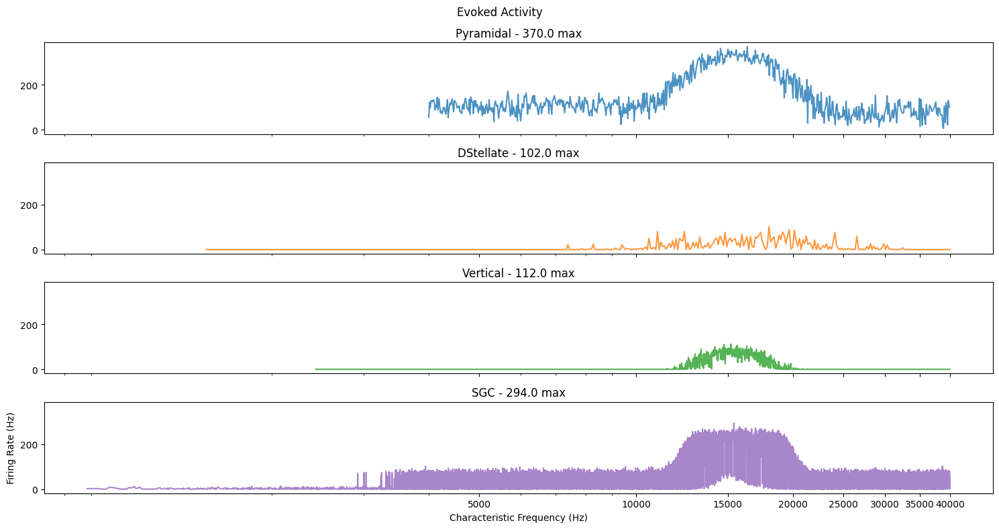

In [14]:
fig, axs = plt.subplots(4,1,figsize=(15,8), sharex=True, sharey=True)
axs = axs.ravel()

axs[0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
            color=colors['pyramidal'], zorder=13, alpha=0.8, label='pyramidal')
axs[0].set_title(f"Pyramidal - {np.max(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])} max")     
# axs[0].legend(loc='upper right')

axs[1].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
            color=colors['dstellate'], zorder=13, alpha=0.8, label='dstellate')
axs[1].set_title(f"DStellate - {np.max(norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)])} max")
# axs[1].legend(loc='upper right')

axs[2].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
            color=colors['vertical'], zorder=13, alpha=0.8, label='vertical')
axs[2].set_title(f"Vertical - {np.max(norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)])} max")
# axs[2].legend(loc='upper right')

axs[3].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
            color=colors['sgc'], zorder=13, alpha=0.8, label='sgc')
axs[3].set_title(f"SGC - {np.max(norm_data_frs['evoked_rates']['sgc'][1][(freq,level)])} max")
# axs[3].legend(loc='upper right')

axs[-1].set_xlabel('Characteristic Frequency (Hz)')
axs[-1].set_ylabel('Firing Rate (Hz)')

axs[0].set_xscale('log')
axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs[0].xaxis.set_major_formatter(ScalarFormatter())

fig.suptitle('Evoked Activity')
fig.tight_layout()

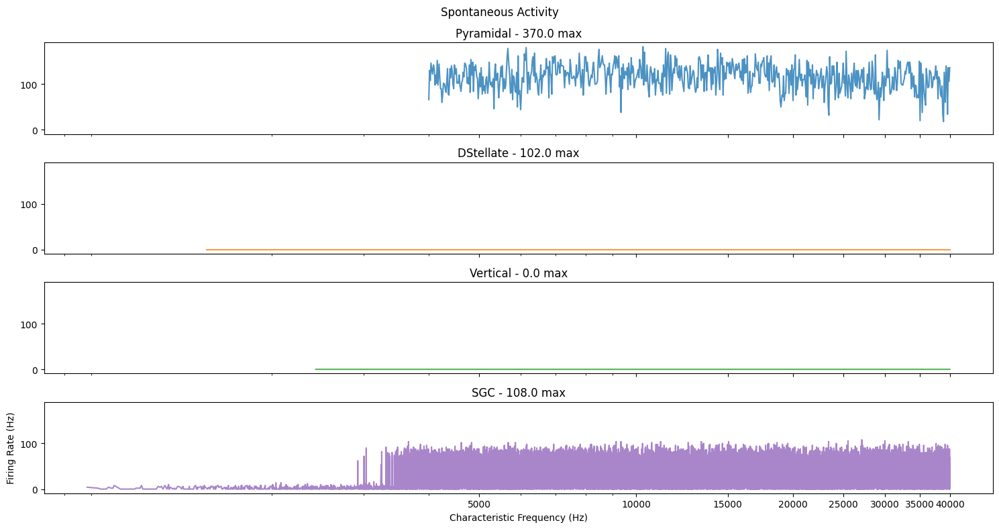

In [15]:
fig, axs = plt.subplots(4,1,figsize=(15,8), sharex=True, sharey=True)
axs = axs.ravel()

axs[0].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
            color=colors['pyramidal'], zorder=13, alpha=0.8, label='pyramidal')
axs[0].set_title(f"Pyramidal - {np.max(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])} max")     
# axs[0].legend(loc='upper right')

axs[1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
            color=colors['dstellate'], zorder=13, alpha=0.8, label='dstellate')
axs[1].set_title(f"DStellate - {np.max(norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)])} max")
# axs[1].legend(loc='upper right')

axs[2].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
            color=colors['vertical'], zorder=13, alpha=0.8, label='vertical')
axs[2].set_title(f"Vertical - {np.max(norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)])} max")
# axs[2].legend(loc='upper right')

axs[3].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
            color=colors['sgc'], zorder=13, alpha=0.8, label='sgc')
axs[3].set_title(f"SGC - {np.max(norm_data_frs['spont_rates']['sgc'][1][(freq,level)])} max")
# axs[3].legend(loc='upper right')

axs[-1].set_xlabel('Characteristic Frequency (Hz)')
axs[-1].set_ylabel('Firing Rate (Hz)')

axs[0].set_xscale('log')
axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs[0].xaxis.set_major_formatter(ScalarFormatter())

fig.suptitle('Spontaneous Activity')
fig.tight_layout()

## Hearing Loss @ 30kHz

In [18]:
loss_limit = 30000

In [19]:
freq = 22000
level = 60
nreps = 5

In [28]:
cohcs = np.arange(0,1.1,0.2)
cihcs = np.arange(0,1.1,0.2)
sgn_losses = np.arange(20,60,10)

### Pyramidal Rates

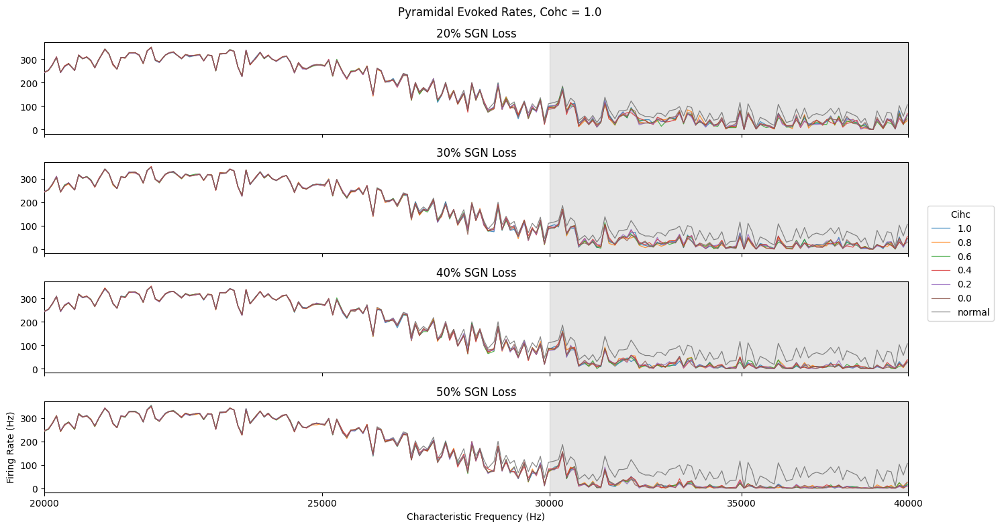

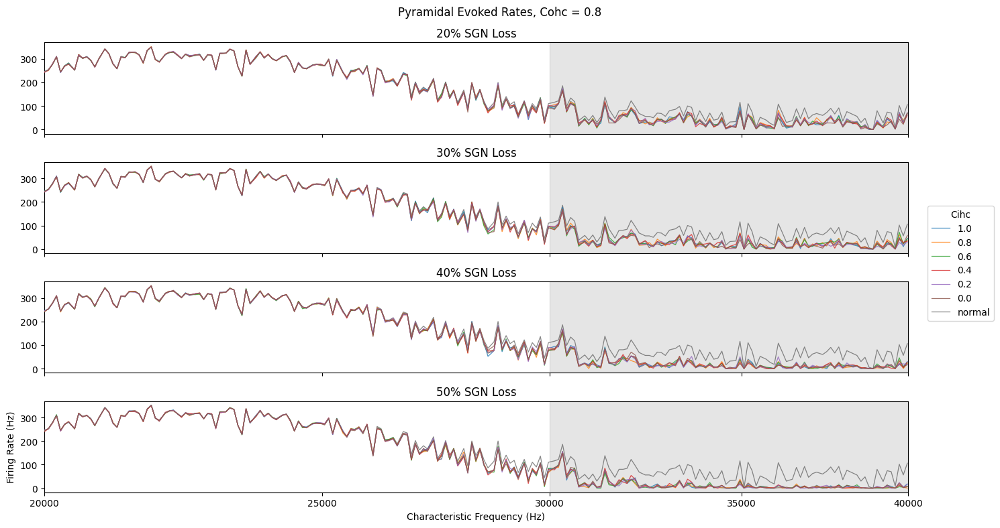

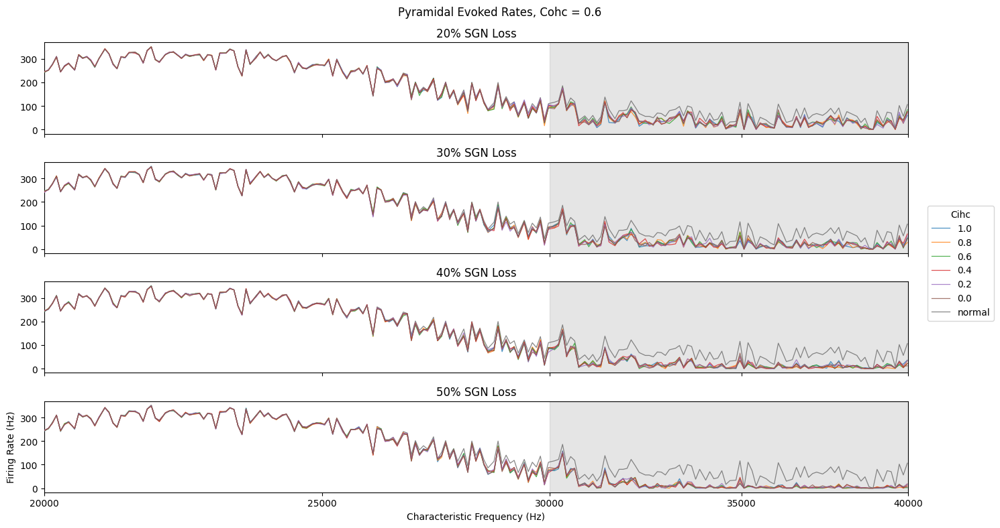

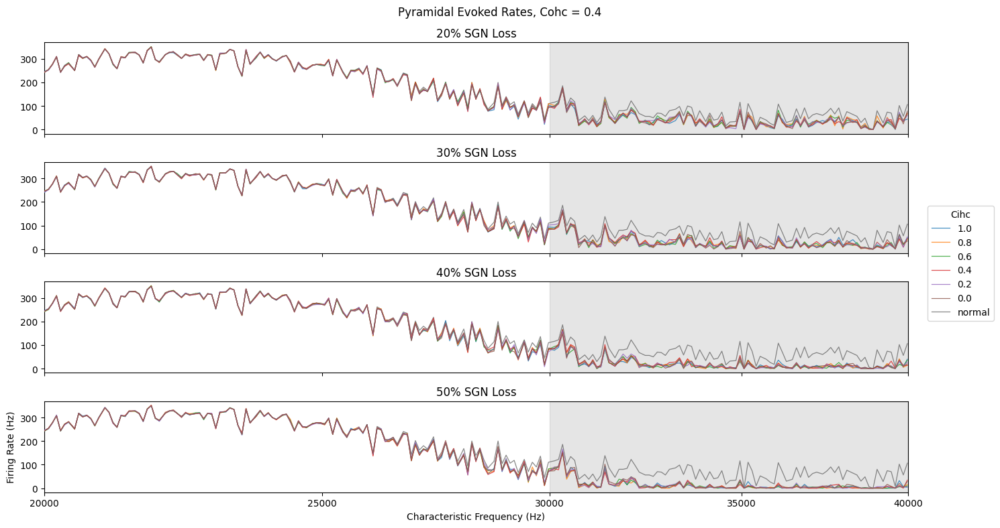

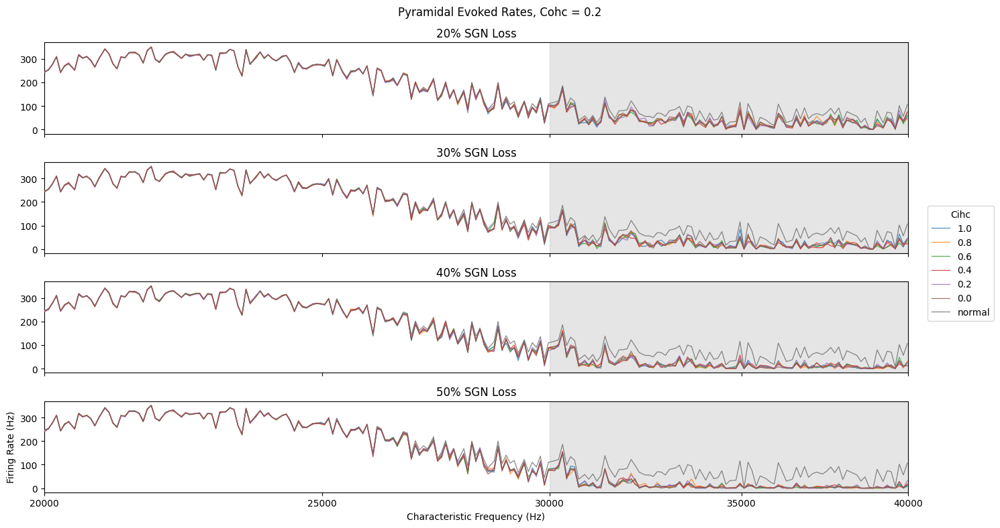

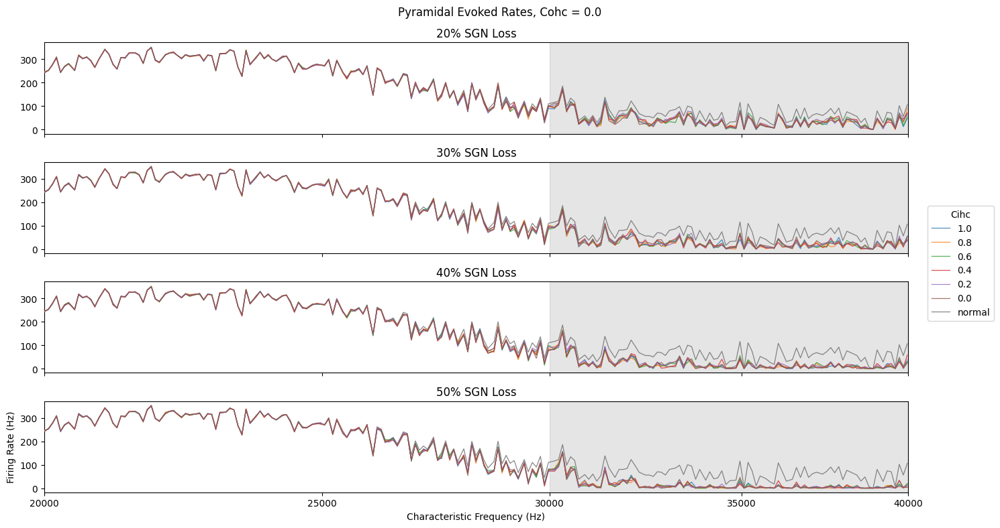

In [ ]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

for cohc in cohcs[::-1]:

    cohc = np.round(cohc, 1)

    nrows = len(sgn_losses)
    fig, axs = plt.subplots(nrows,1,figsize=(15,2*nrows), sharex=True, sharey=True)
    axs = axs.ravel()

    for i, sgn_loss in enumerate(sgn_losses):

        ax = axs[i]

        for cihc in cihcs[::-1]:

            cihc = np.round(cihc, 1)

            hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
            data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
            data_frs = pickle.load(open(data_path, 'rb'))

            ax.plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
        
        ax.set_title(f"{sgn_loss}% SGN Loss")
        
        ax.plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')

    axs[-1].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1].set_ylabel('Firing Rate (Hz)')

    for ax in axs:
        ax.axvspan(30000,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0].set_xscale('log')
    axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0].xaxis.set_major_formatter(ScalarFormatter())

    axs[0].set_xlim([20000,40000])

    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)
    
    fig.suptitle(f'Pyramidal Evoked Rates, Cohc = {cohc}')
    fig.tight_layout(rect=[0,0,0.93,1])

    

### All Cell Rates

/tmp/ipykernel_3871840/3188339923.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True, sharey=True)


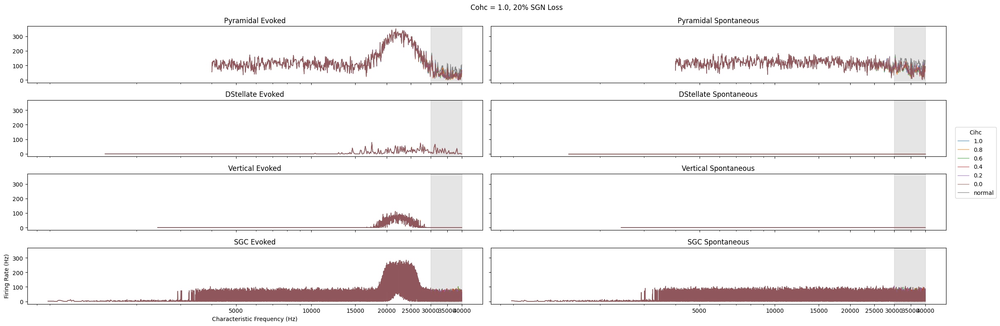

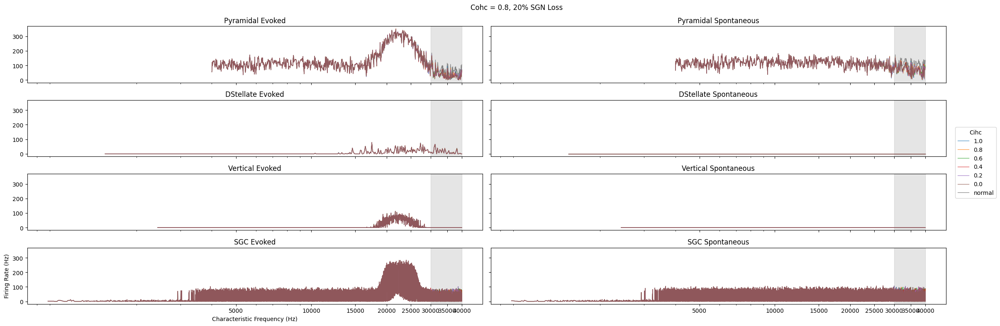

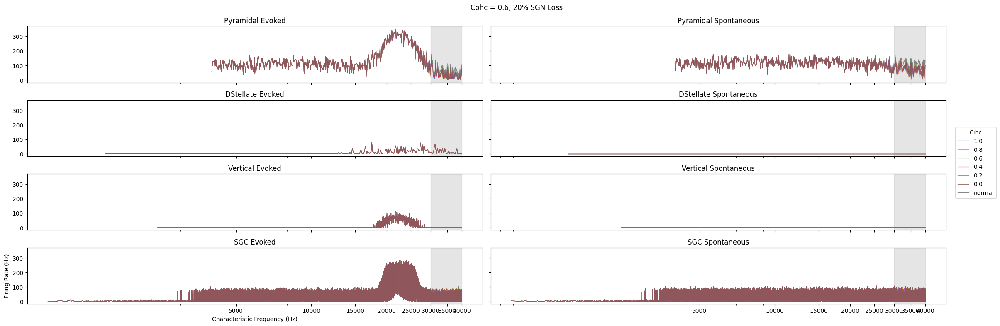

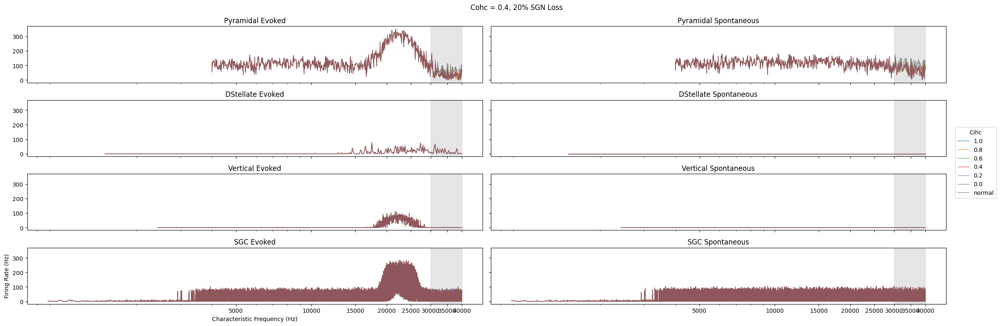

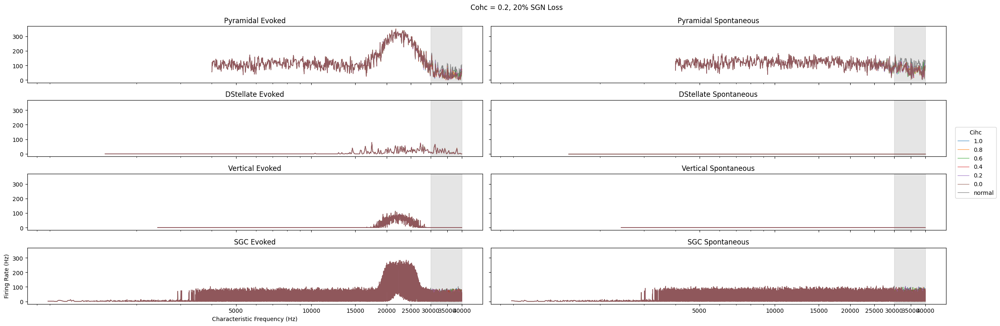

...

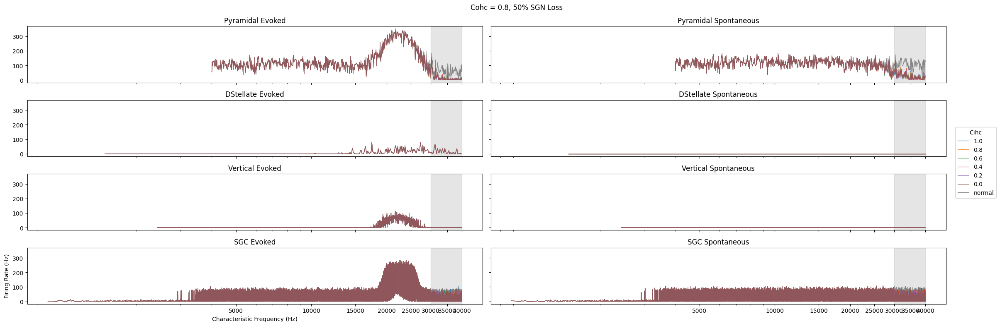

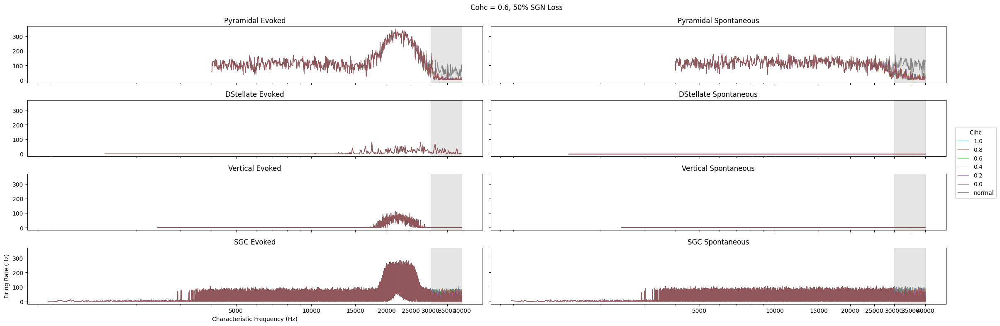

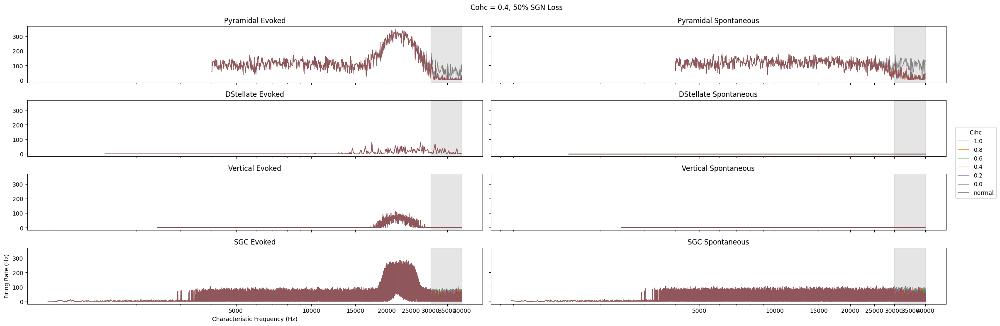

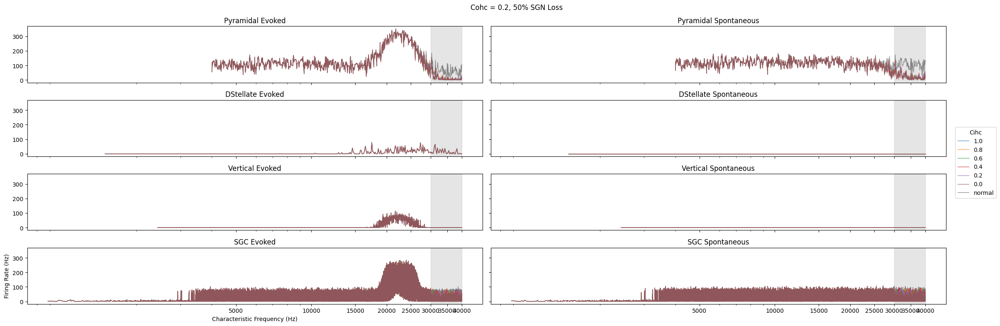

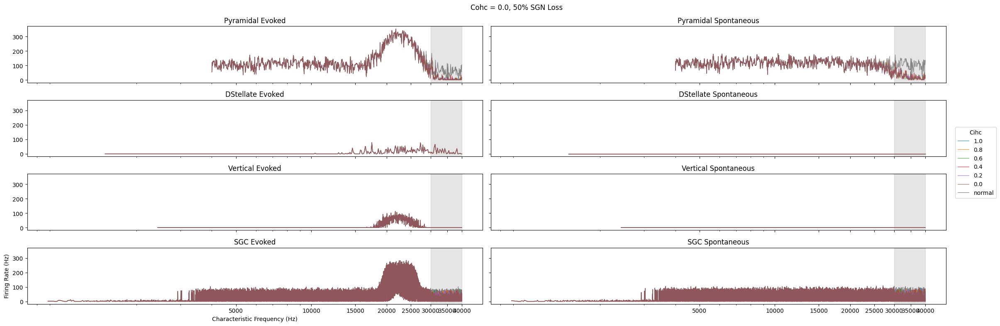

In [ ]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

for sgn_loss in sgn_losses:

    for cohc in cohcs[::-1]:

        cohc = np.round(cohc, 1)

        fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True, sharey=True)

        for i, cihc in enumerate(cihcs[::-1]):

            cihc = np.round(cihc, 1)

            hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
            data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
            data_frs = pickle.load(open(data_path, 'rb'))

            axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[0,0].set_title(f"Pyramidal Evoked")
            axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[0,1].set_title(f"Pyramidal Spontaneous")

            axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[1,0].set_title(f"DStellate Evoked")
            axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[1,1].set_title(f"DStellate Spontaneous")

            axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                         zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[2,0].set_title(f"Vertical Evoked")
            axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                         zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[2,1].set_title(f"Vertical Spontaneous")

            axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[3,0].set_title(f"SGC Evoked")
            axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[3,1].set_title(f"SGC Spontaneous")


        axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
        axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
        axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        
        axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
        axs[-1,0].set_ylabel('Firing Rate (Hz)')

        # axs[0].set_xlim(29000,40000)
        # axs[0].set_ylim(top=200)

        for ax in axs.ravel():
            ax.axvspan(30000,40000, color='grey', alpha=0.2, zorder=1)

        # for i in range(1,4):
        axs[0,0].set_xscale('log')
        axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
        axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

        handles, labels = axs[0,1].get_legend_handles_labels()
        fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)
        
        fig.suptitle(f'Cohc = {cohc}, {sgn_loss}% SGN Loss')
        fig.tight_layout(rect=[0,0,0.92,1])

        

### Targeted

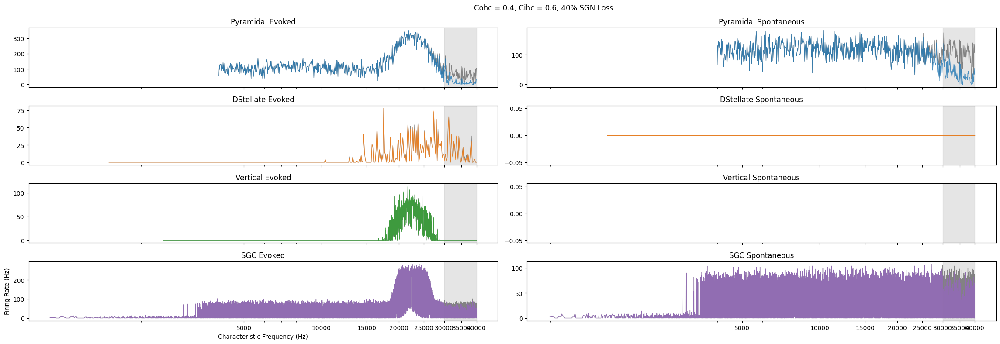

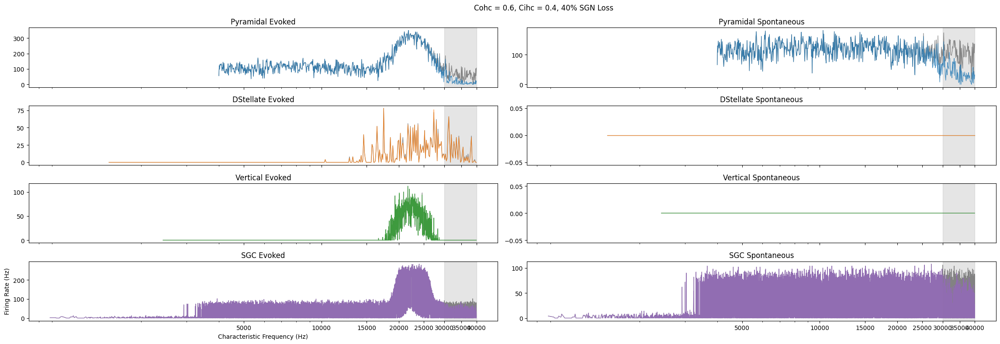

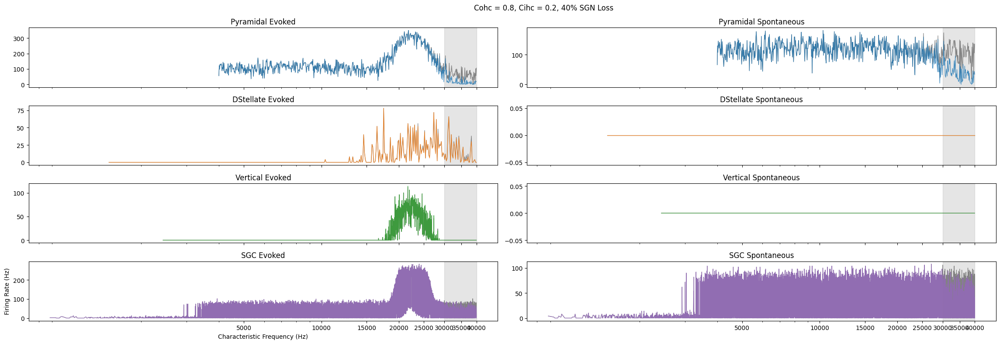

In [ ]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

loss_params = [(0.4, 0.6, 40), (0.6, 0.4, 40), (0.8, 0.2, 40)]  # Cohc, Cihc, % SGN loss

for cohc, cihc, sgn_loss in loss_params:

    cohc = np.round(cohc, 1)
    cihc = np.round(cihc, 1)

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'Cohc = {cohc}, Cihc = {cihc}, {sgn_loss}% SGN Loss')
    fig.tight_layout(rect=[0,0,0.92,1])


    


### Homeostatic Factor

/tmp/ipykernel_4012618/659188381.py:14: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)


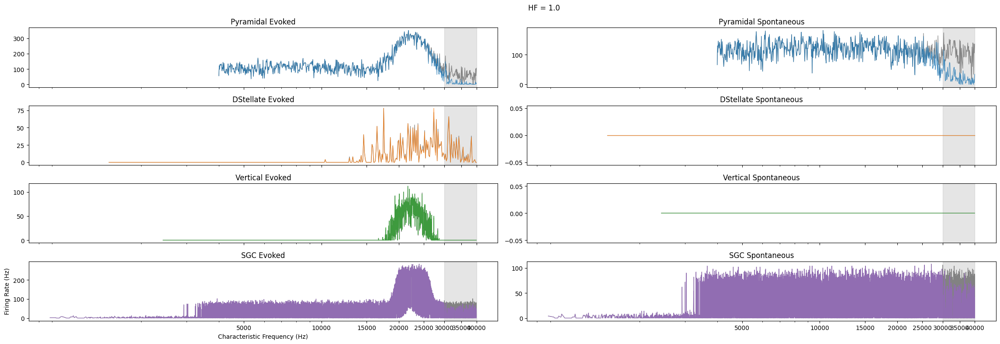

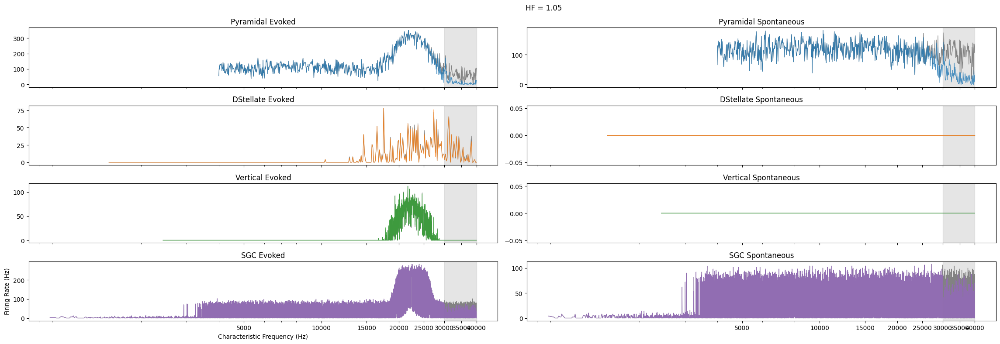

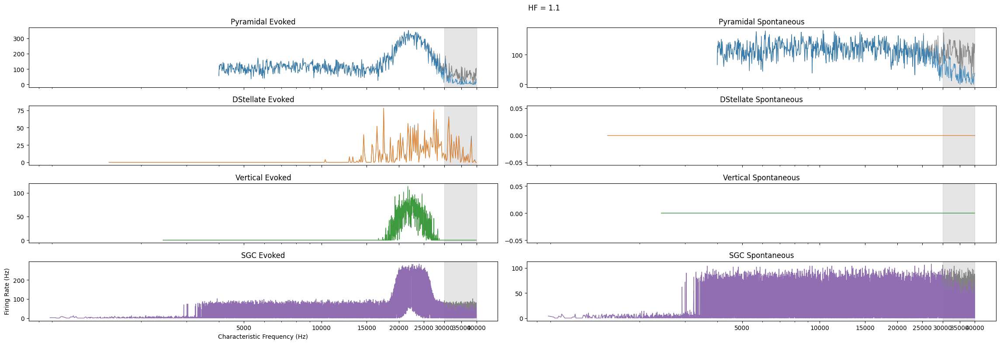

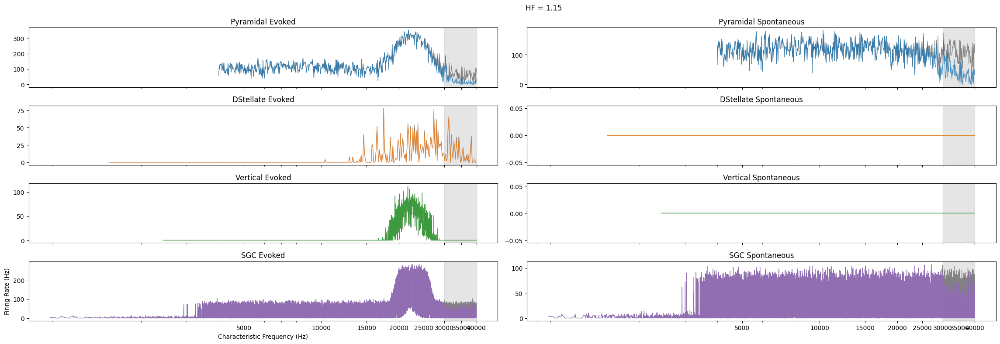

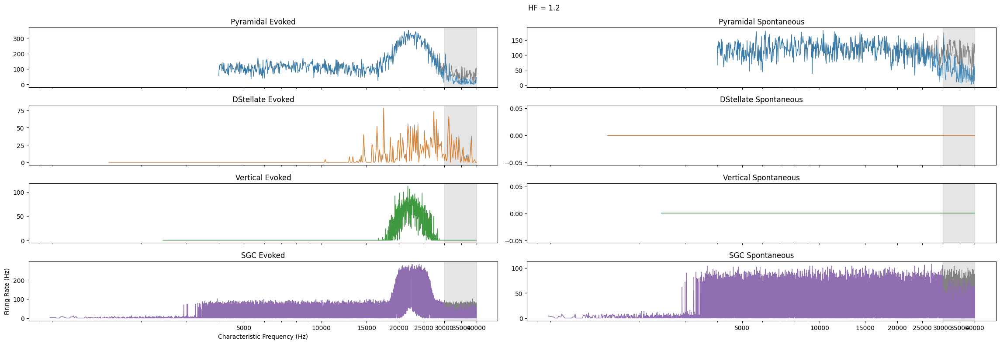

...

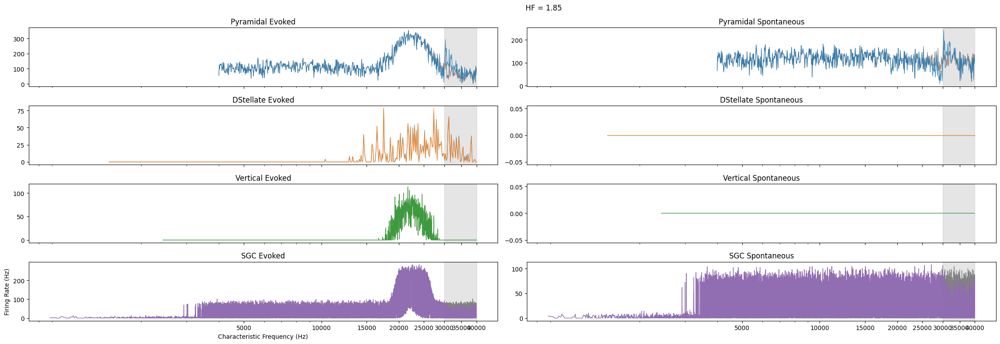

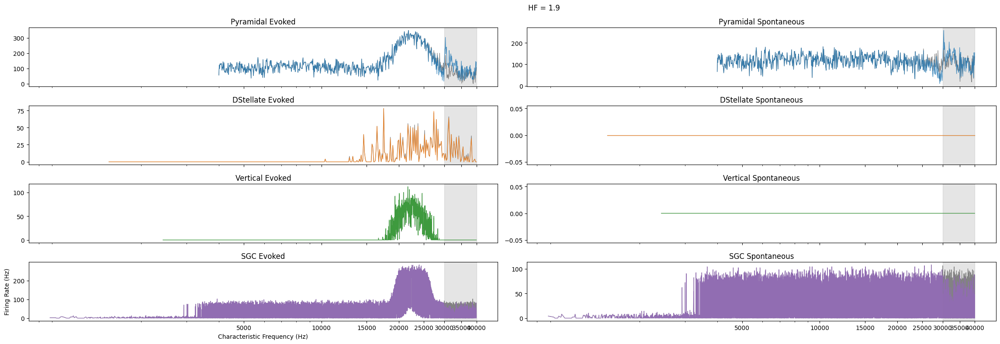

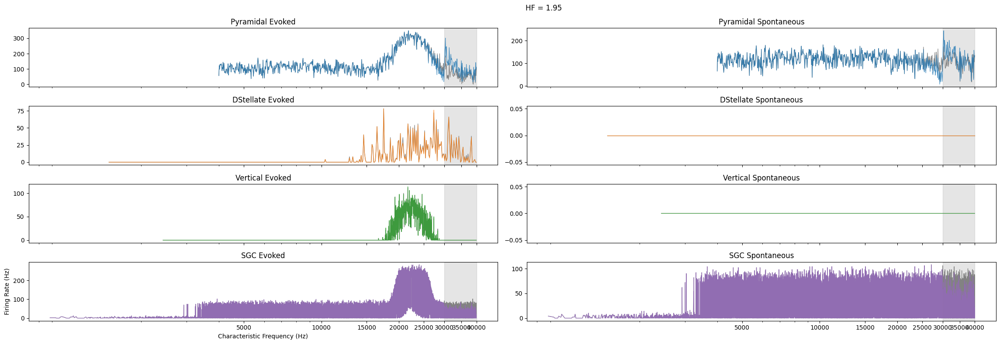

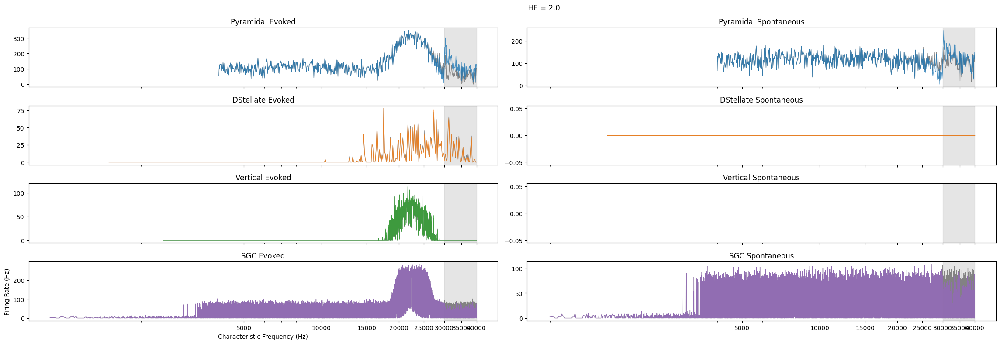

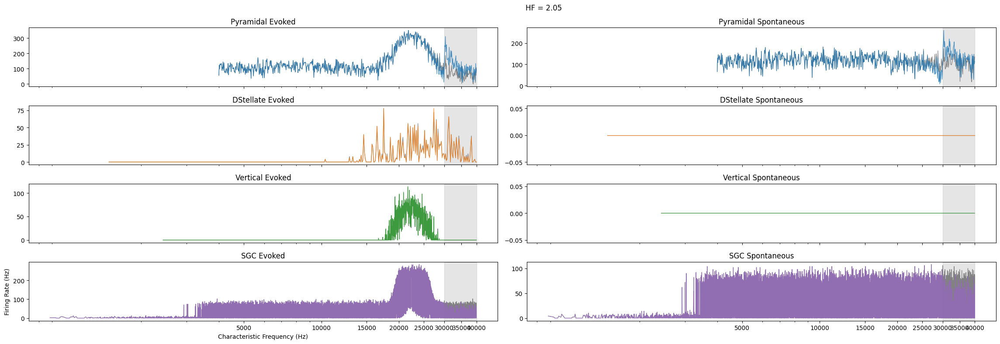

In [19]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'


cohc = 0.8
cihc = 0.8
sgn_loss = 50

hfs = np.arange(1,2.1,0.05)
hfs = [f"{float(hf):.1f}" if float(hf).is_integer() else f"{hf:g}" for hf in np.arange(1,2.1,0.05)]
hfs[-2] = '2.0'

for hf in hfs:

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'HF = {hf}')
    fig.tight_layout(rect=[0,0,0.92,1])


    


## Hearing Loss @ 15 kHz

In [16]:
loss_limit = 15000

In [17]:
freq = 22000
level = 60
nreps = 5

In [18]:
cohcs = np.arange(0,1.1,0.2)
cihcs = np.arange(0,1.1,0.2)
sgn_losses = np.arange(20,60,10)

### Pyramidal Rates

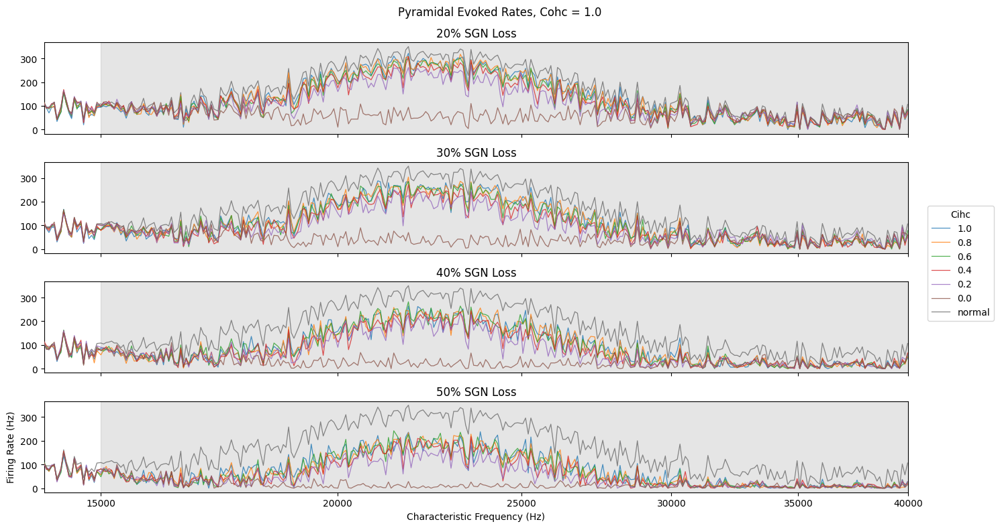

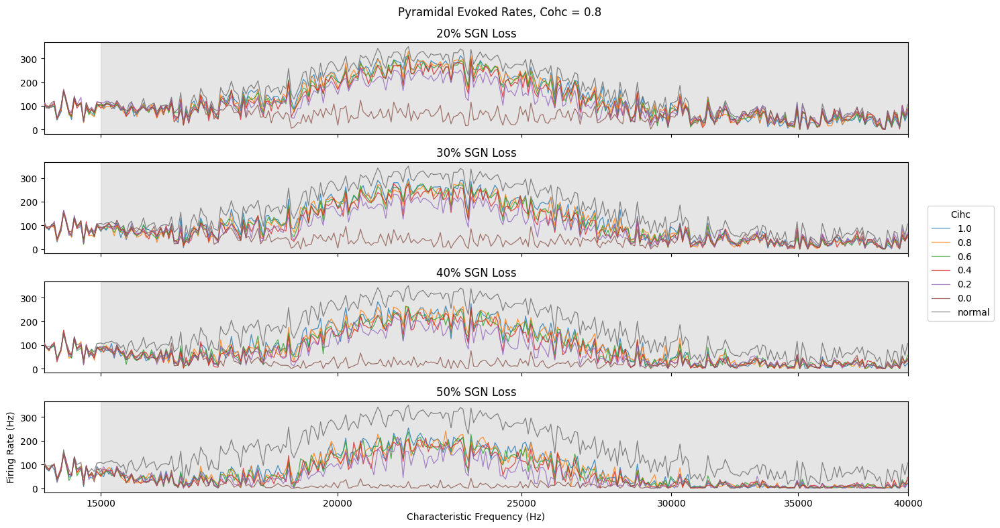

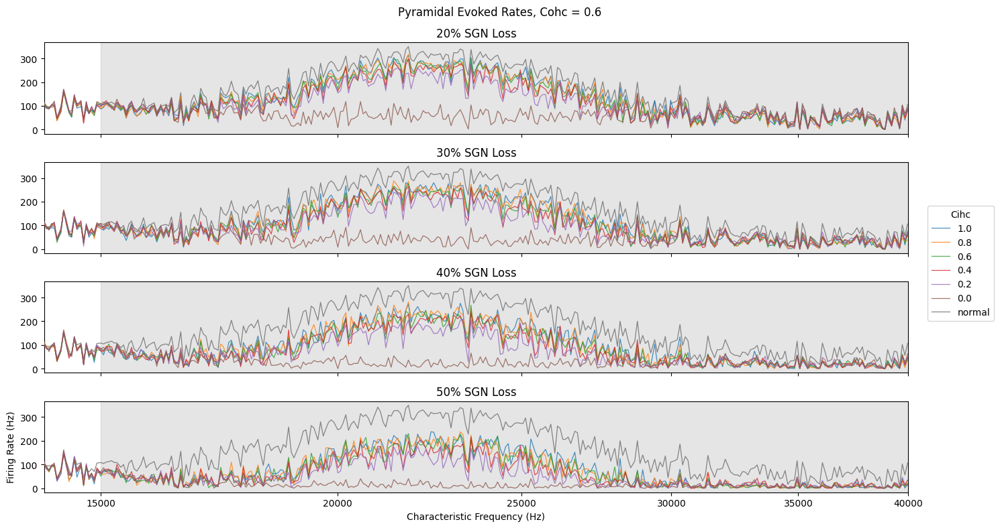

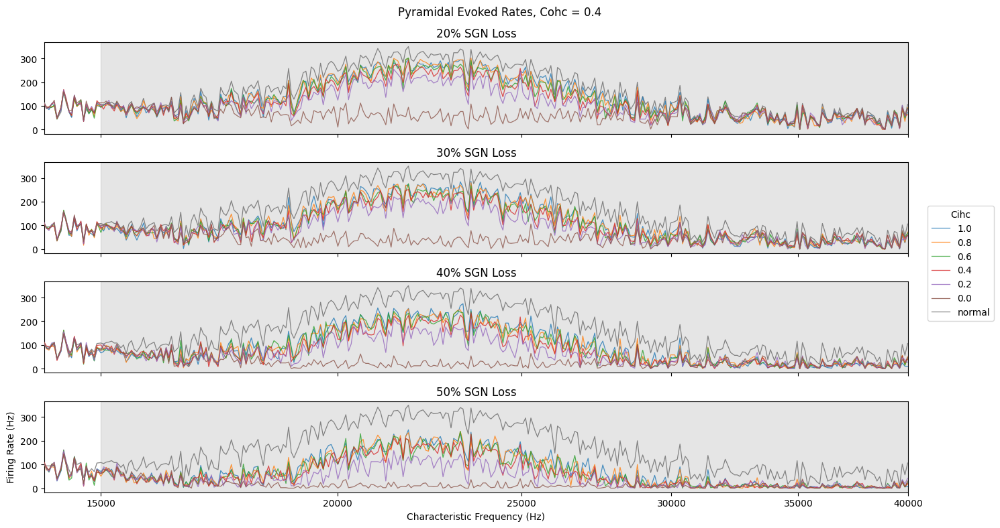

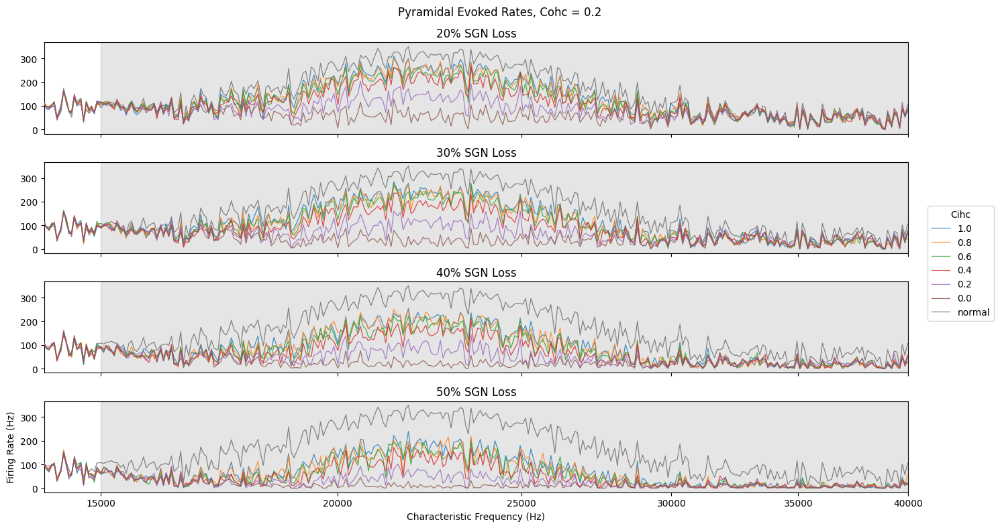

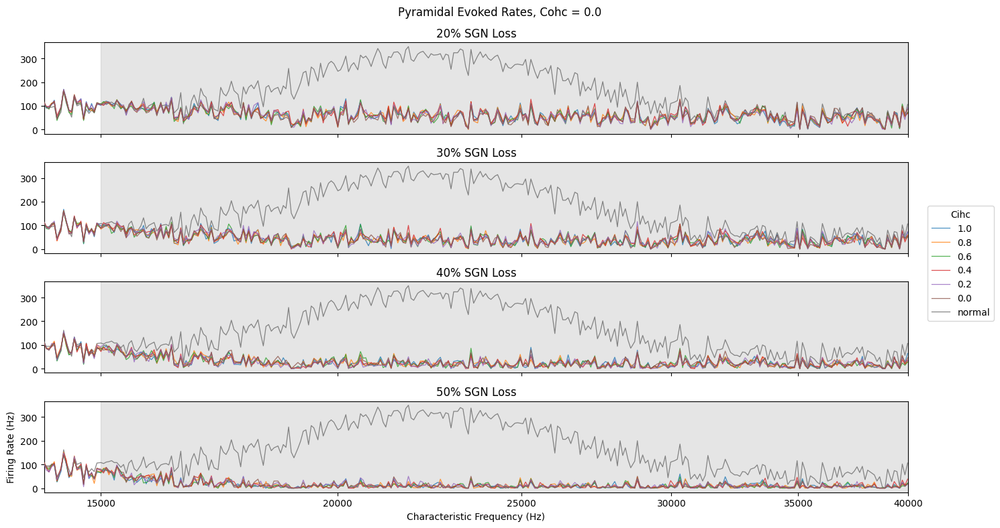

In [31]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

for cohc in cohcs[::-1]:

    cohc = np.round(cohc, 1)

    nrows = len(sgn_losses)
    fig, axs = plt.subplots(nrows,1,figsize=(15,2*nrows), sharex=True, sharey=True)
    axs = axs.ravel()

    for i, sgn_loss in enumerate(sgn_losses):

        ax = axs[i]

        for cihc in cihcs[::-1]:

            cihc = np.round(cihc, 1)

            hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
            data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
            data_frs = pickle.load(open(data_path, 'rb'))

            ax.plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
        
        ax.set_title(f"{sgn_loss}% SGN Loss")
        
        ax.plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')

    axs[-1].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1].set_ylabel('Firing Rate (Hz)')

    for ax in axs:
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0].set_xscale('log')
    axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0].xaxis.set_major_formatter(ScalarFormatter())

    axs[0].set_xlim([14000,40000])

    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)
    
    fig.suptitle(f'Pyramidal Evoked Rates, Cohc = {cohc}')
    fig.tight_layout(rect=[0,0,0.93,1])

    

    

### All Cell Rates

/tmp/ipykernel_3871840/3817181370.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True, sharey=True)


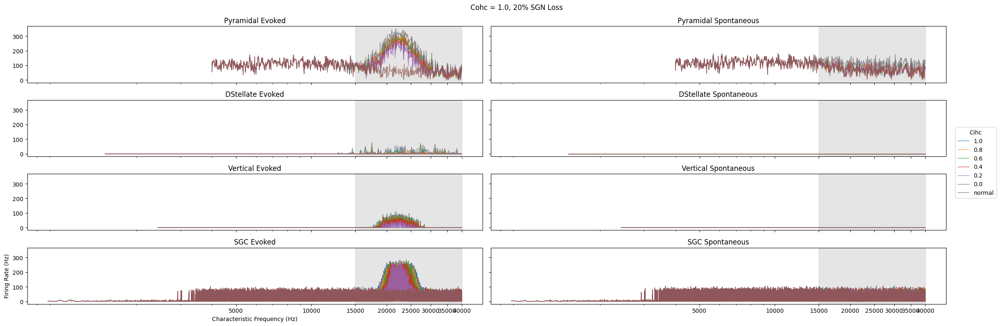

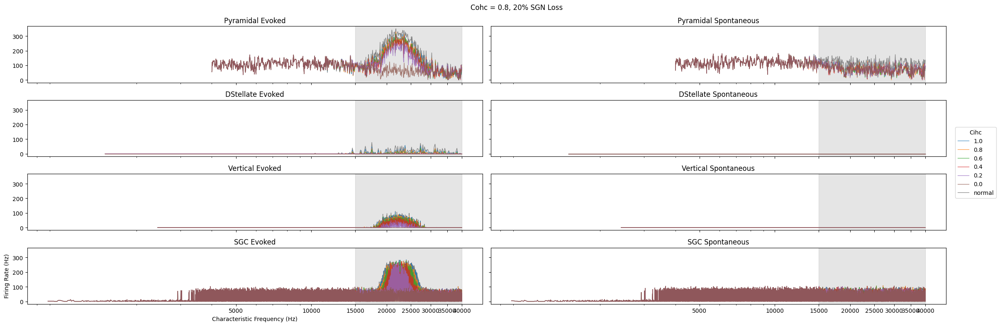

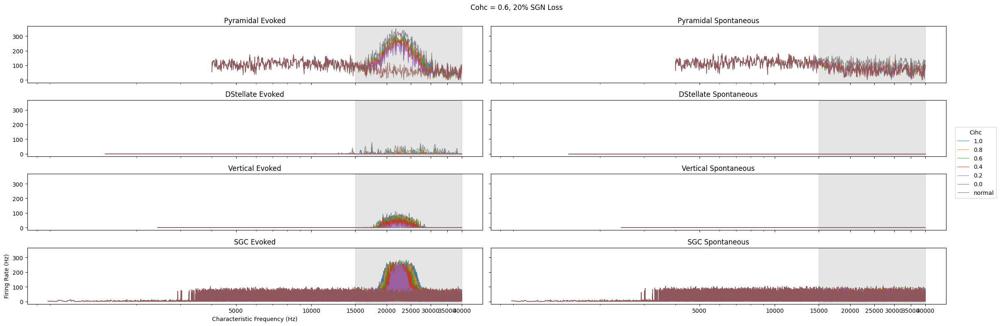

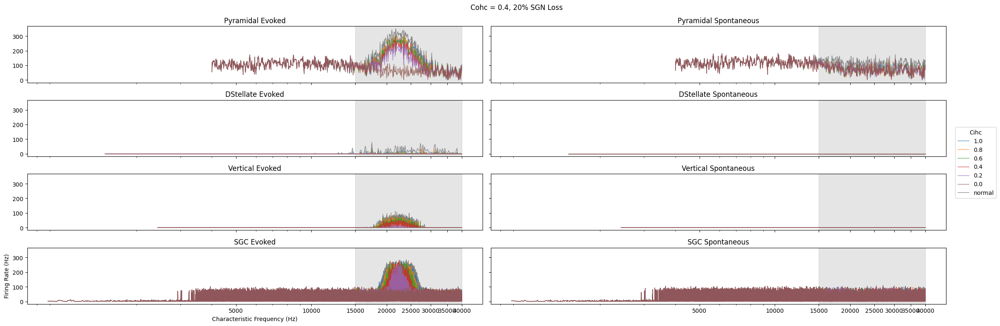

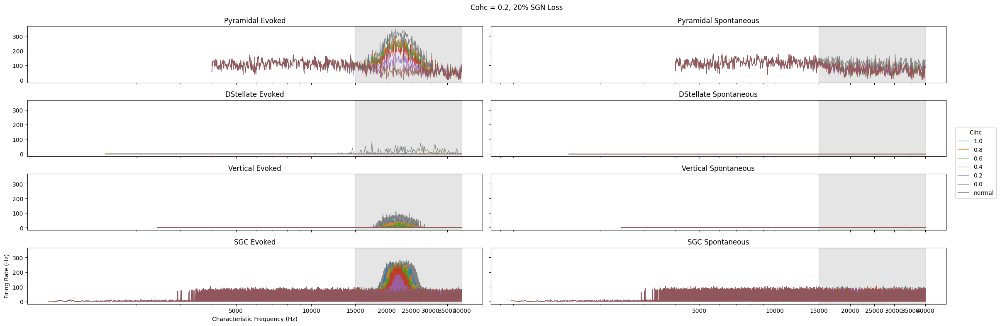

...

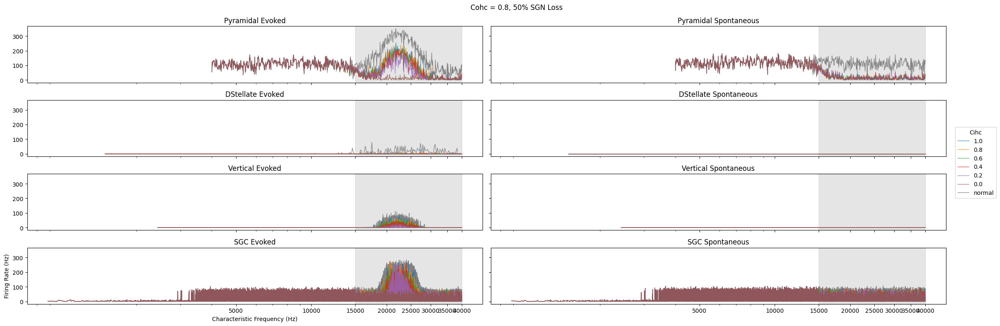

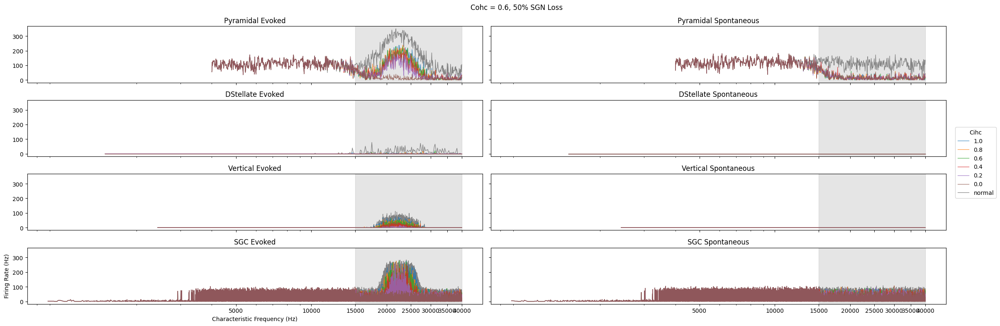

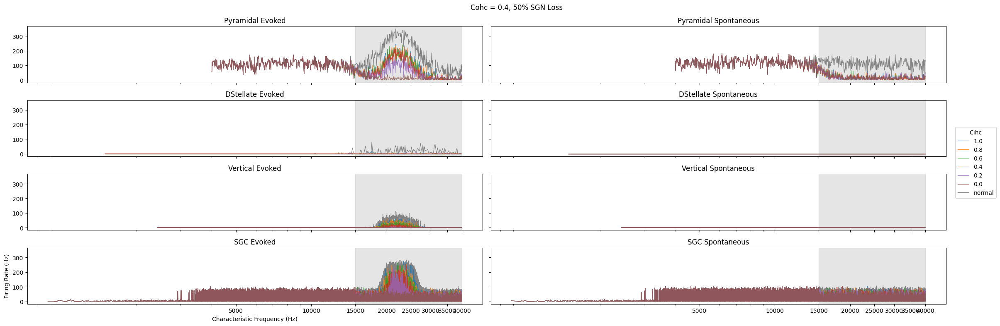

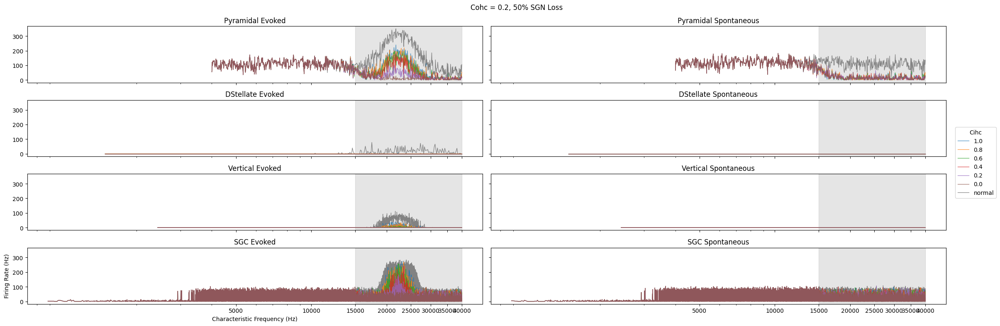

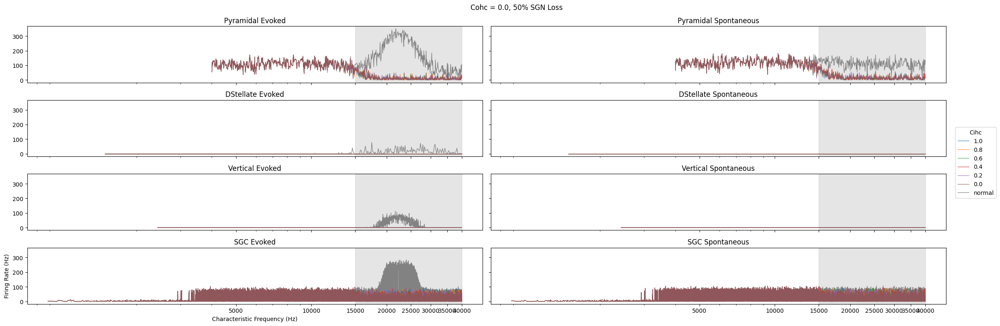

In [33]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

for sgn_loss in sgn_losses:

    for cohc in cohcs[::-1]:

        cohc = np.round(cohc, 1)

        fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True, sharey=True)

        for i, cihc in enumerate(cihcs[::-1]):

            cihc = np.round(cihc, 1)

            hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
            data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
            data_frs = pickle.load(open(data_path, 'rb'))

            axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[0,0].set_title(f"Pyramidal Evoked")
            axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[0,1].set_title(f"Pyramidal Spontaneous")

            axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[1,0].set_title(f"DStellate Evoked")
            axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[1,1].set_title(f"DStellate Spontaneous")

            axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                         zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[2,0].set_title(f"Vertical Evoked")
            axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                         zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[2,1].set_title(f"Vertical Spontaneous")

            axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[3,0].set_title(f"SGC Evoked")
            axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[3,1].set_title(f"SGC Spontaneous")


        axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
        axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
        axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        
        axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
        axs[-1,0].set_ylabel('Firing Rate (Hz)')

        # axs[0].set_xlim(29000,40000)
        # axs[0].set_ylim(top=200)

        for ax in axs.ravel():
            ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

        # for i in range(1,4):
        axs[0,0].set_xscale('log')
        axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
        axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

        handles, labels = axs[0,1].get_legend_handles_labels()
        fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)
        
        fig.suptitle(f'Cohc = {cohc}, {sgn_loss}% SGN Loss')
        fig.tight_layout(rect=[0,0,0.92,1])
        # break
    # break

### Targeted

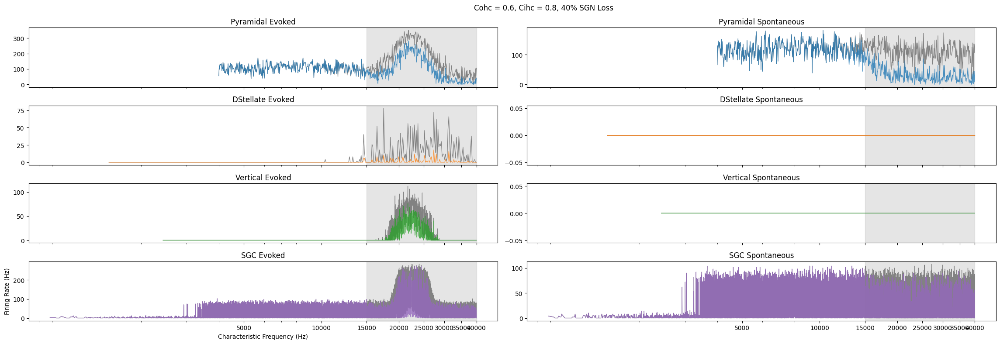

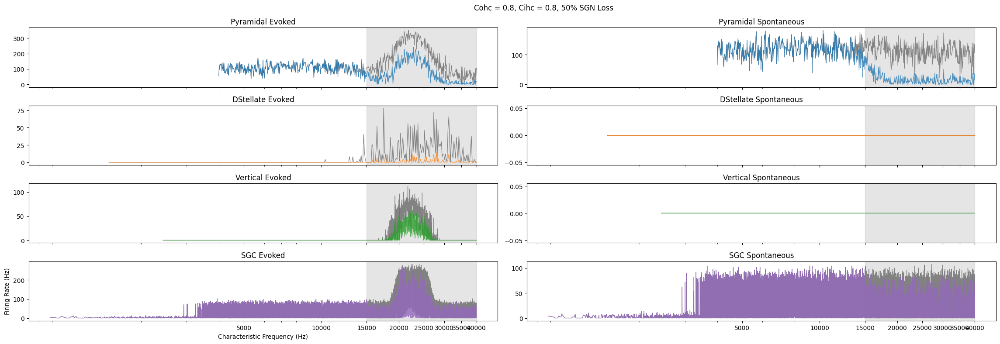

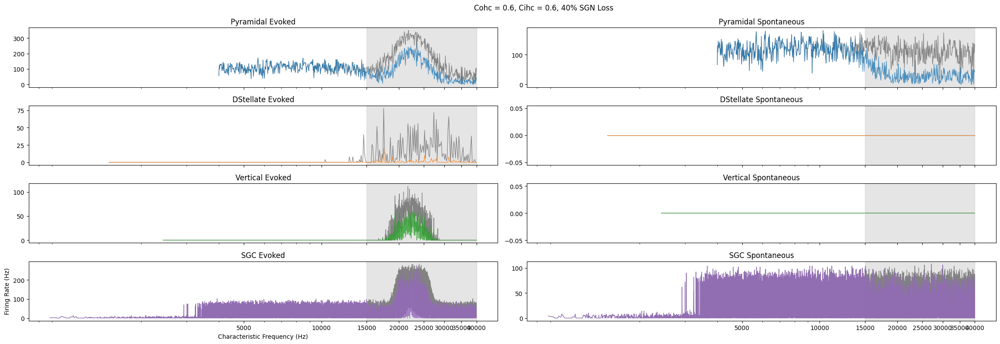

In [61]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

loss_params = [(0.6, 0.8, 40), (0.8, 0.8, 50), (0.6, 0.6, 40)]  # Cohc, Cihc, % SGN loss

for cohc, cihc, sgn_loss in loss_params:

    cohc = np.round(cohc, 1)
    cihc = np.round(cihc, 1)

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'Cohc = {cohc}, Cihc = {cihc}, {sgn_loss}% SGN Loss')
    fig.tight_layout(rect=[0,0,0.92,1])


    


### Homeostatic Plasticity

#### 22 kHz input

/tmp/ipykernel_4018664/659188381.py:14: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)


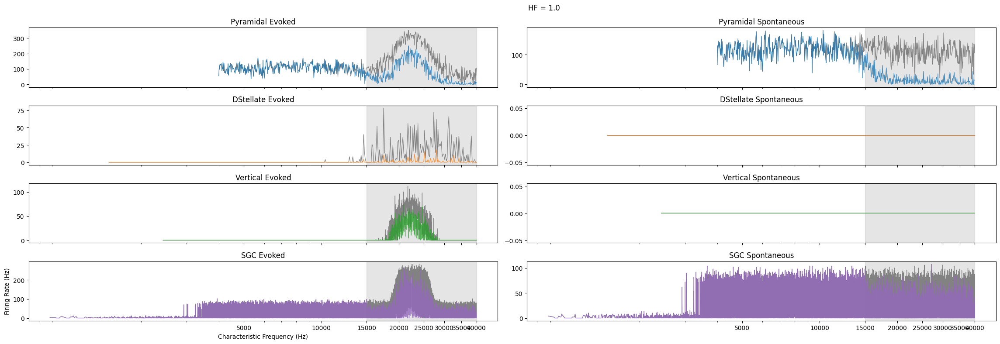

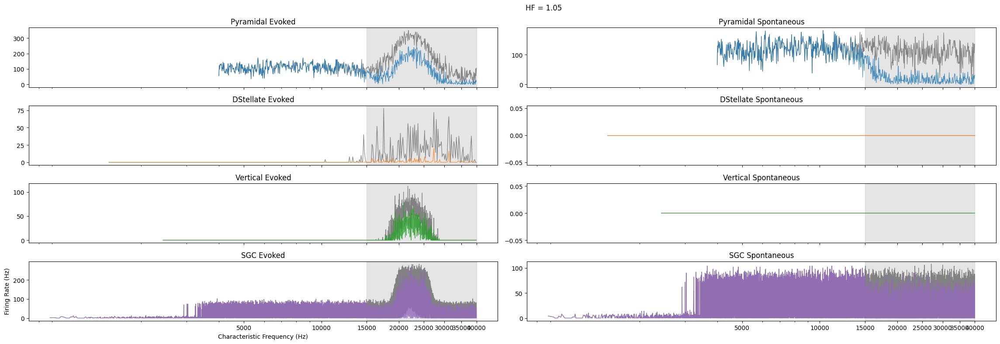

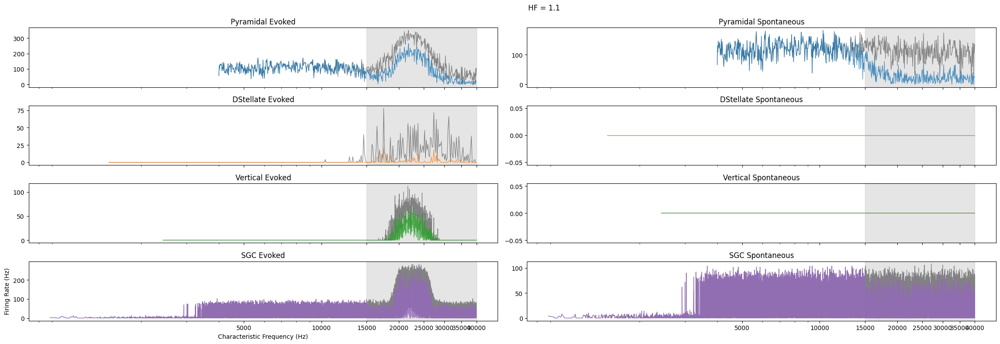

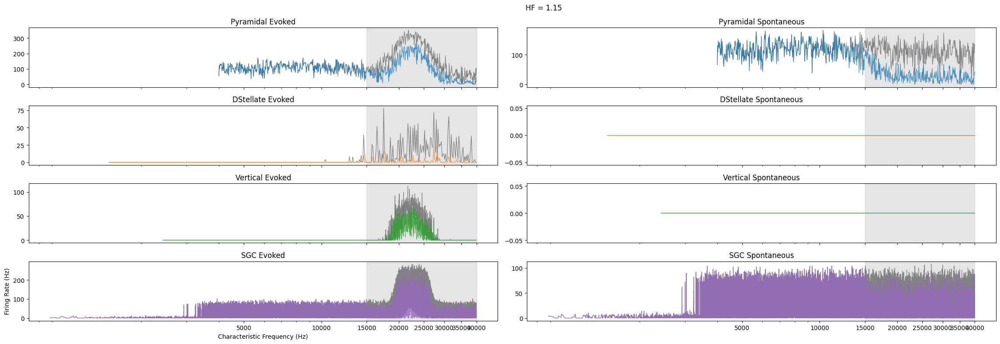

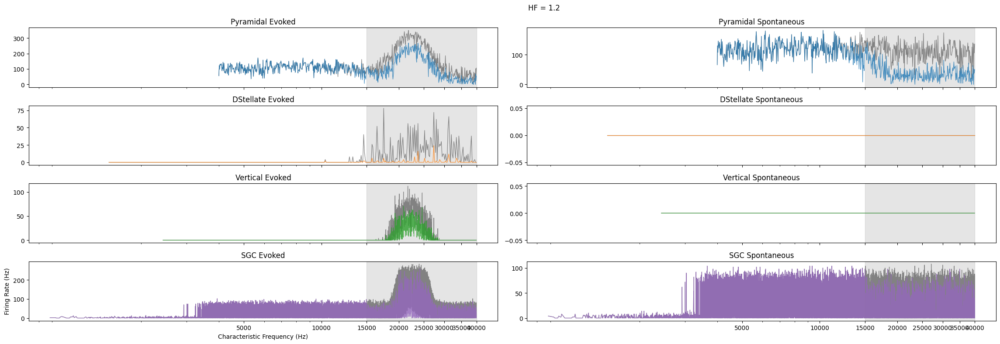

...

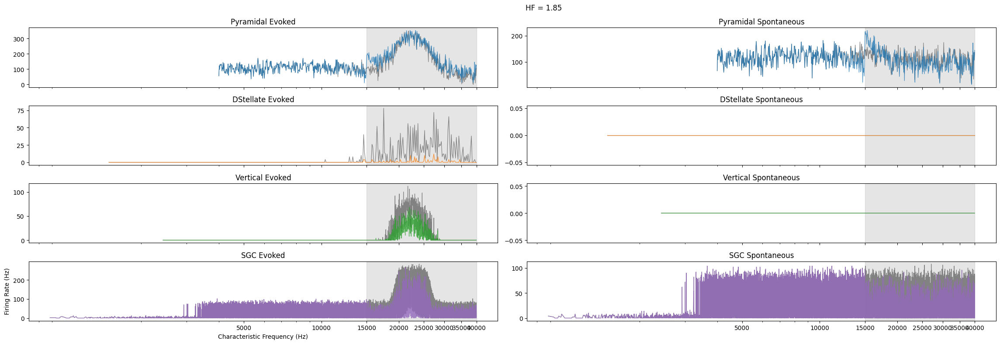

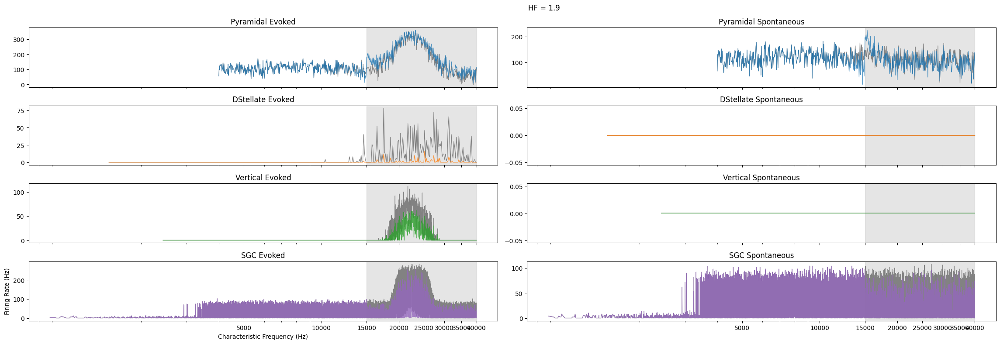

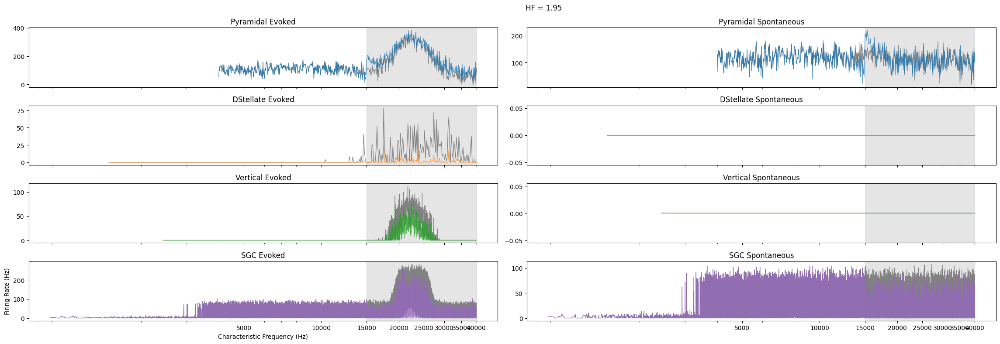

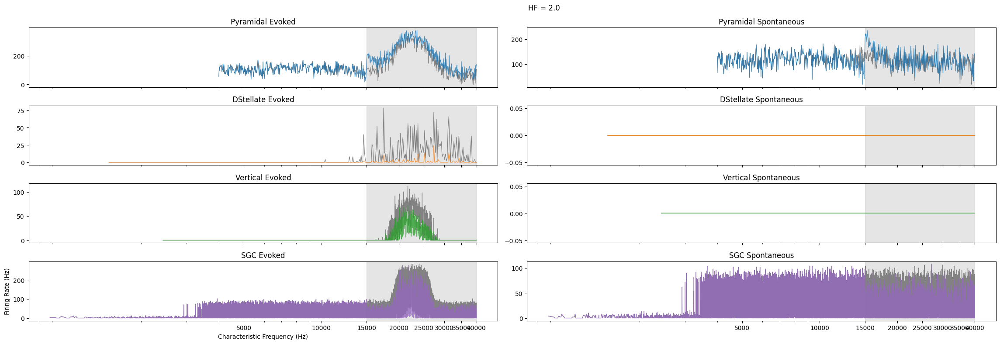

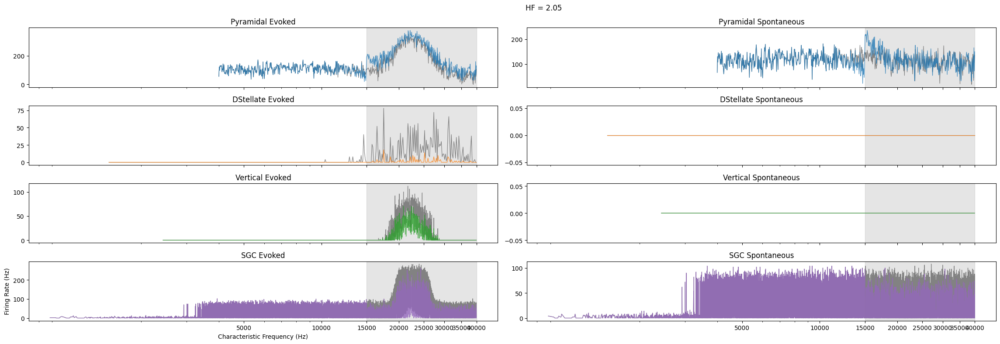

In [25]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'


cohc = 0.8
cihc = 0.8
sgn_loss = 50

hfs = np.arange(1,2.1,0.05)
hfs = [f"{float(hf):.1f}" if float(hf).is_integer() else f"{hf:g}" for hf in np.arange(1,2.1,0.05)]
hfs[-2] = '2.0'

for hf in hfs:

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'HF = {hf}')
    fig.tight_layout(rect=[0,0,0.92,1])


    


#### 15 kHz input

/tmp/ipykernel_3980677/3073434059.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)


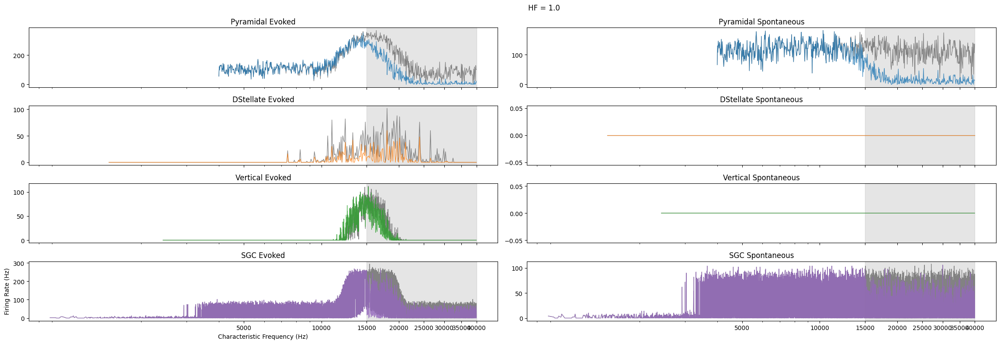

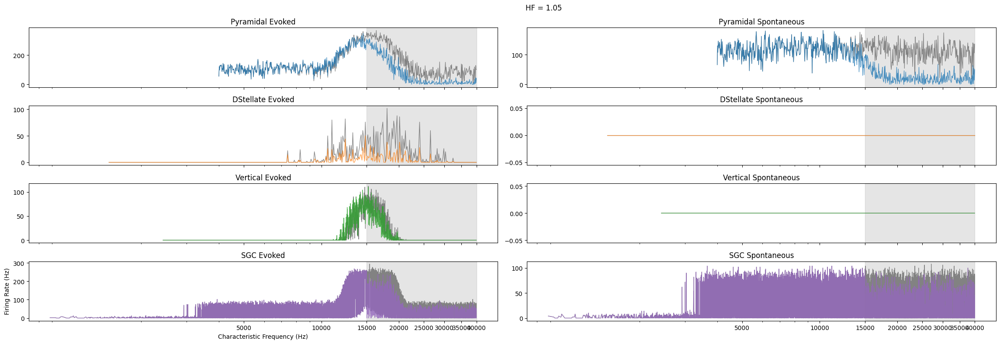

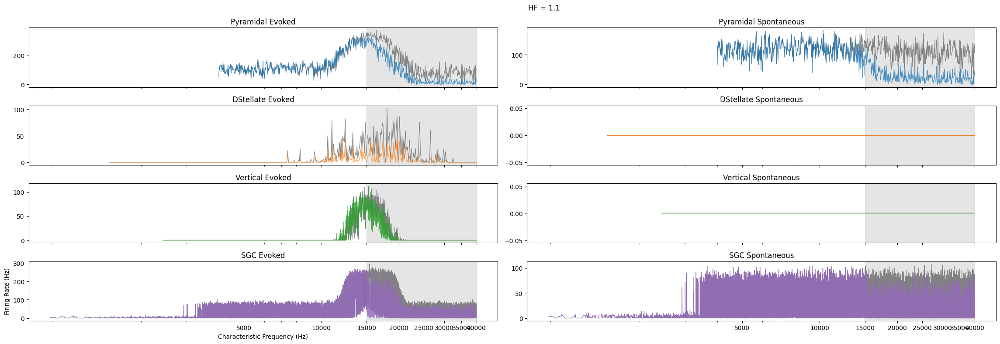

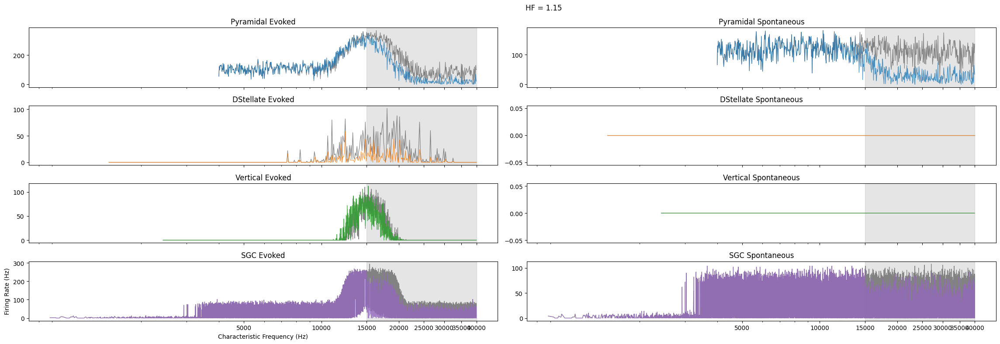

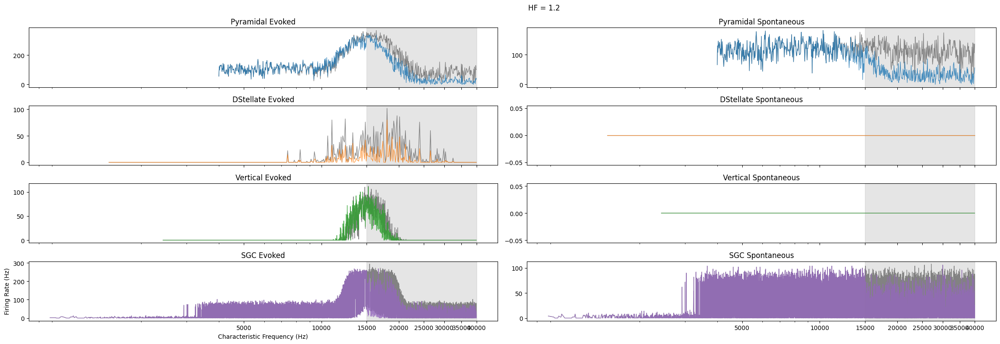

...

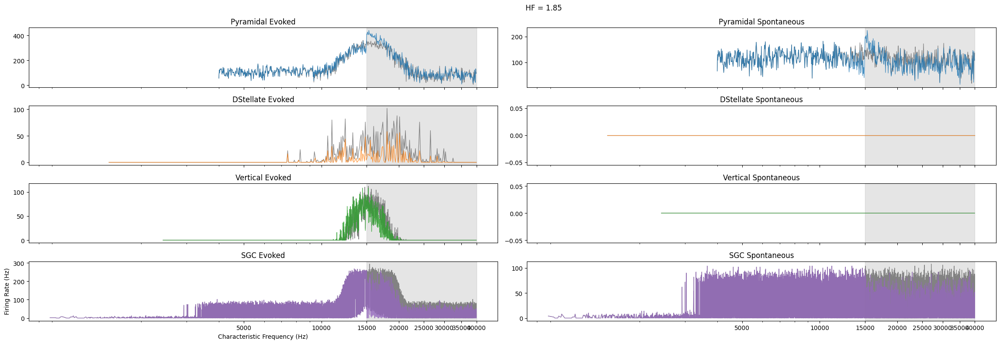

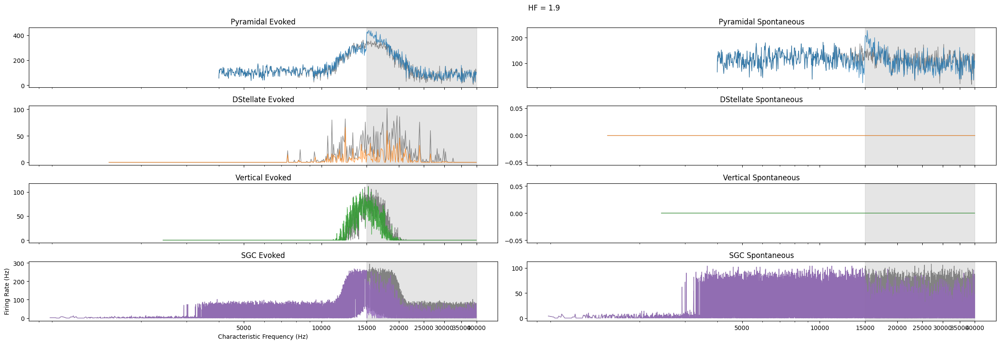

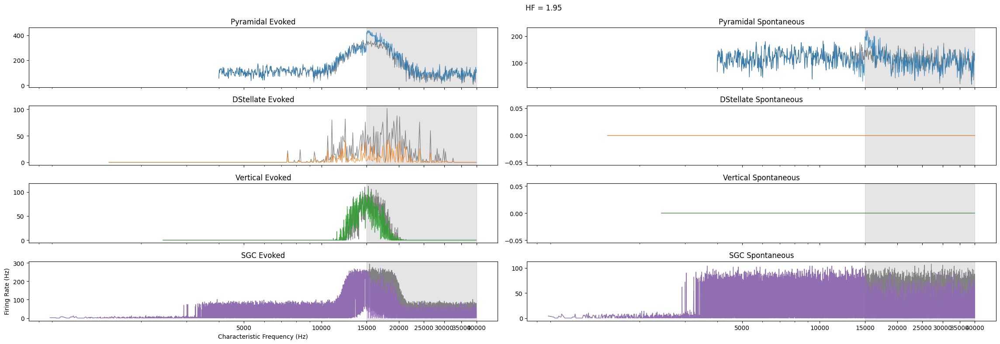

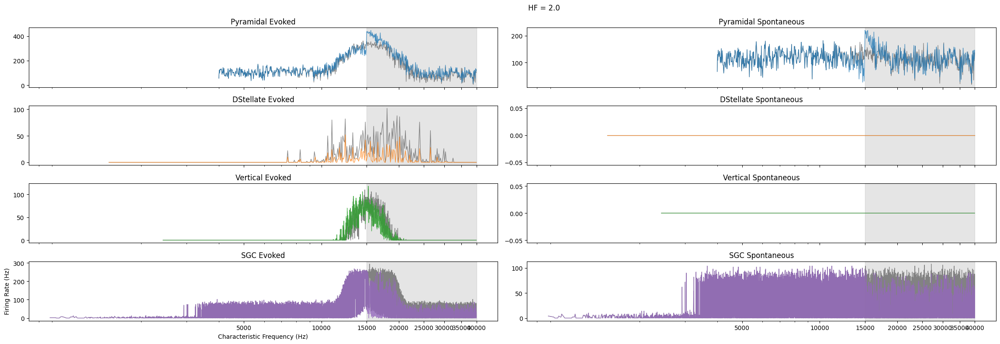

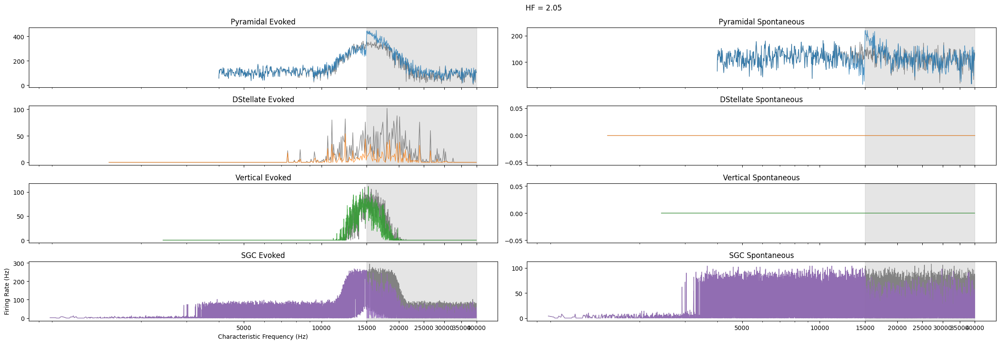

In [19]:
freq = 15000
loss_limit = 15000

sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

cohc = 0.8
cihc = 0.8
sgn_loss = 50

hfs = np.arange(1,2.1,0.05)
hfs = [f"{float(hf):.1f}" if float(hf).is_integer() else f"{hf:g}" for hf in hfs]
hfs[-2] = '2.0'

for hf in hfs:

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'HF = {hf}')
    fig.tight_layout(rect=[0,0,0.92,1])


    


# Type IV

## Normal

In [22]:
freq = 22000
level = 60
nreps = 5
pyr_type = 'IV'

In [23]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'
hearing_dir = os.path.join(sim_dir, 'NORMAL')
data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
norm_data_frs = pickle.load(open(data_path, 'rb'))

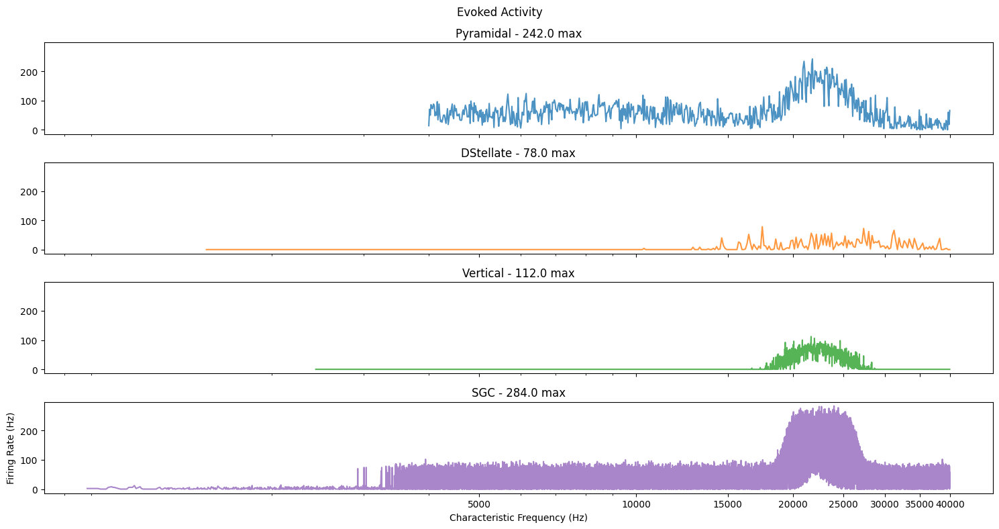

In [24]:
fig, axs = plt.subplots(4,1,figsize=(15,8), sharex=True, sharey=True)
axs = axs.ravel()

axs[0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
            color=colors['pyramidal'], zorder=13, alpha=0.8, label='pyramidal')
axs[0].set_title(f"Pyramidal - {np.max(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])} max")     
# axs[0].legend(loc='upper right')

axs[1].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
            color=colors['dstellate'], zorder=13, alpha=0.8, label='dstellate')
axs[1].set_title(f"DStellate - {np.max(norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)])} max")
# axs[1].legend(loc='upper right')

axs[2].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
            color=colors['vertical'], zorder=13, alpha=0.8, label='vertical')
axs[2].set_title(f"Vertical - {np.max(norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)])} max")
# axs[2].legend(loc='upper right')

axs[3].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
            color=colors['sgc'], zorder=13, alpha=0.8, label='sgc')
axs[3].set_title(f"SGC - {np.max(norm_data_frs['evoked_rates']['sgc'][1][(freq,level)])} max")
# axs[3].legend(loc='upper right')

axs[-1].set_xlabel('Characteristic Frequency (Hz)')
axs[-1].set_ylabel('Firing Rate (Hz)')

axs[0].set_xscale('log')
axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs[0].xaxis.set_major_formatter(ScalarFormatter())

fig.suptitle('Evoked Activity')
fig.tight_layout()

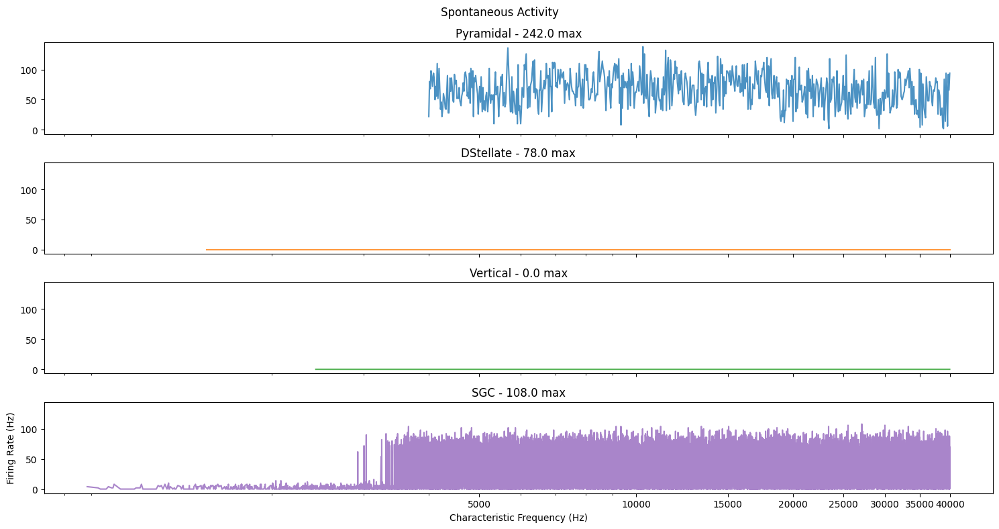

In [25]:
fig, axs = plt.subplots(4,1,figsize=(15,8), sharex=True, sharey=True)
axs = axs.ravel()

axs[0].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
            color=colors['pyramidal'], zorder=13, alpha=0.8, label='pyramidal')
axs[0].set_title(f"Pyramidal - {np.max(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])} max")     
# axs[0].legend(loc='upper right')

axs[1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
            color=colors['dstellate'], zorder=13, alpha=0.8, label='dstellate')
axs[1].set_title(f"DStellate - {np.max(norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)])} max")
# axs[1].legend(loc='upper right')

axs[2].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
            color=colors['vertical'], zorder=13, alpha=0.8, label='vertical')
axs[2].set_title(f"Vertical - {np.max(norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)])} max")
# axs[2].legend(loc='upper right')

axs[3].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
            color=colors['sgc'], zorder=13, alpha=0.8, label='sgc')
axs[3].set_title(f"SGC - {np.max(norm_data_frs['spont_rates']['sgc'][1][(freq,level)])} max")
# axs[3].legend(loc='upper right')

axs[-1].set_xlabel('Characteristic Frequency (Hz)')
axs[-1].set_ylabel('Firing Rate (Hz)')

axs[0].set_xscale('log')
axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs[0].xaxis.set_major_formatter(ScalarFormatter())

fig.suptitle('Spontaneous Activity')
fig.tight_layout()

## Hearing Loss @ 30 kHz

In [26]:
loss_limit = 30000

### All Cell Rates

/tmp/ipykernel_3870616/319123588.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True, sharey=True)


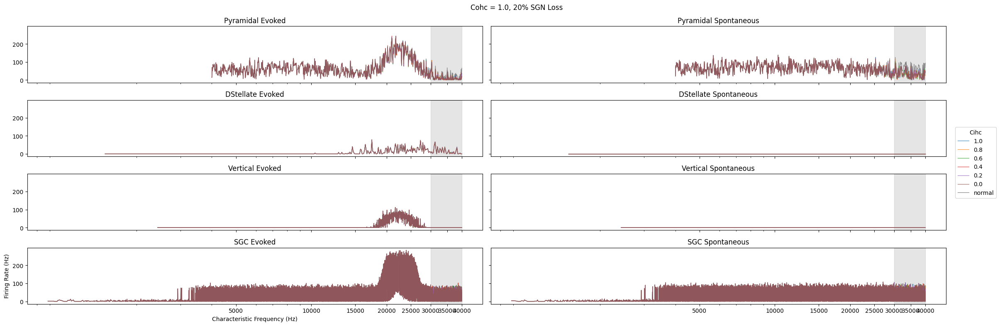

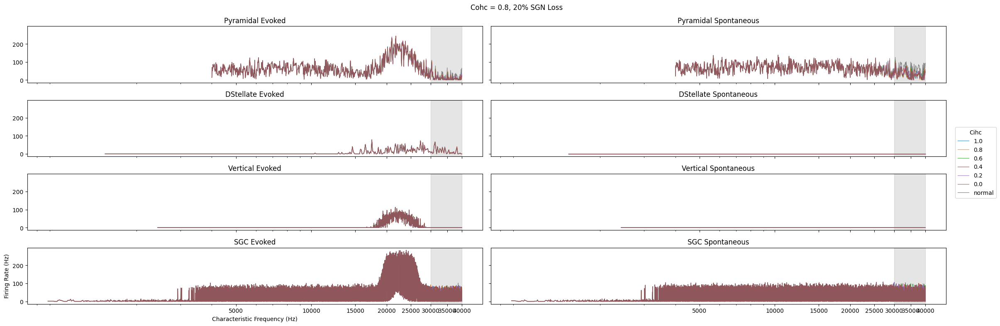

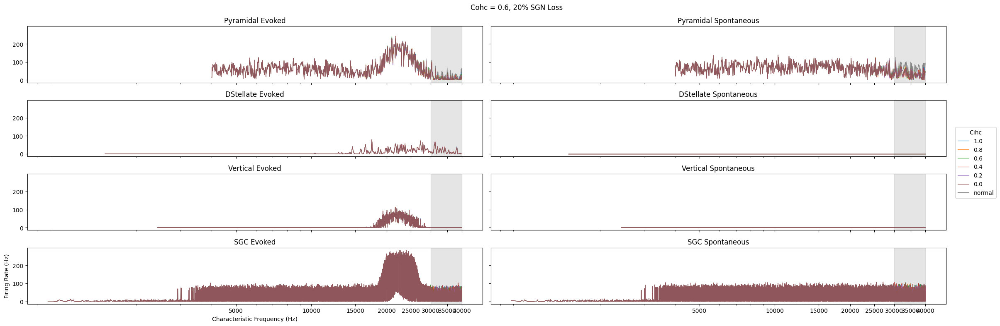

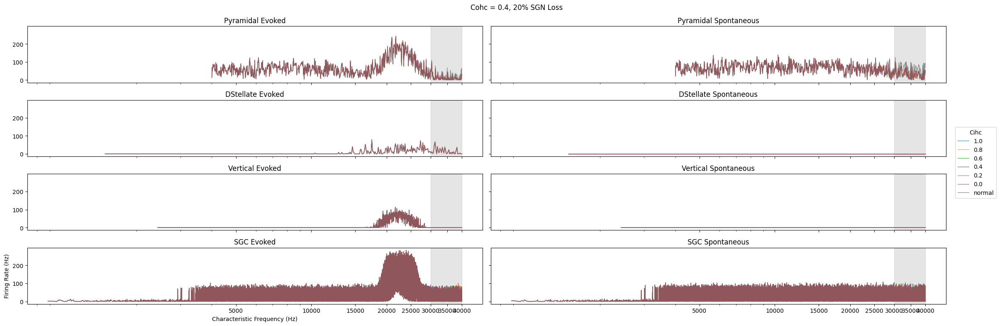

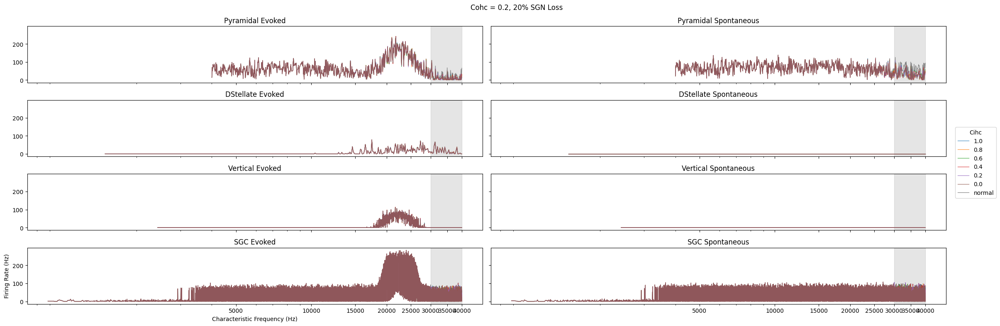

...

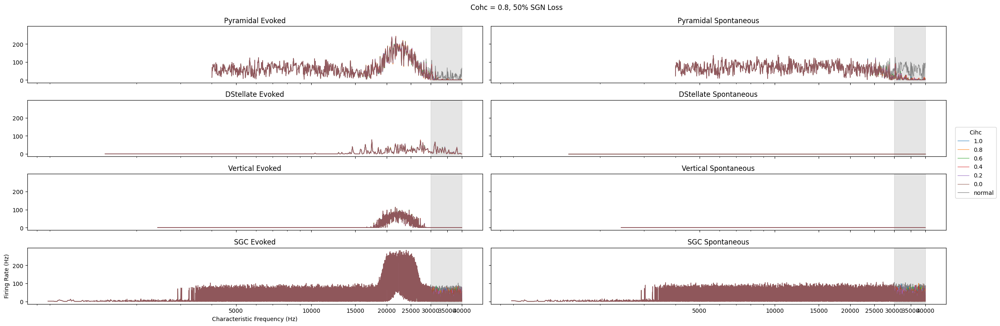

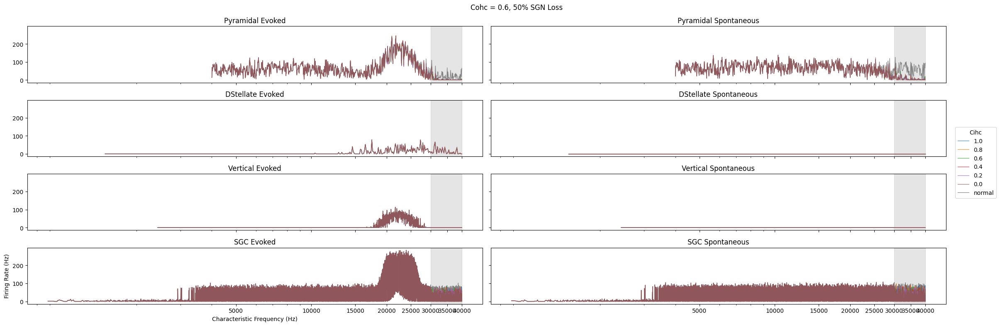

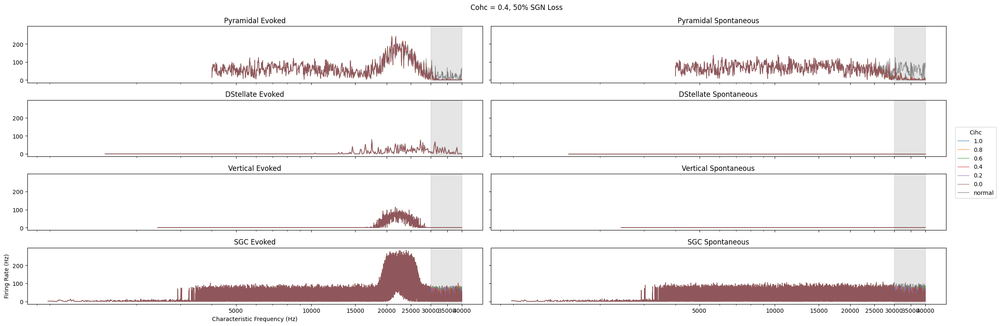

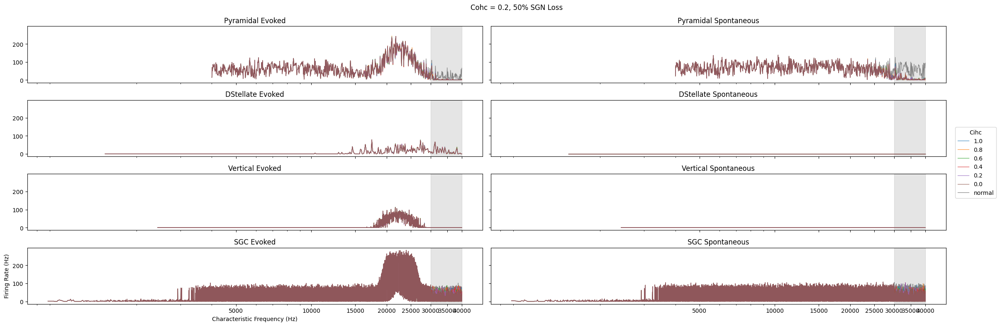

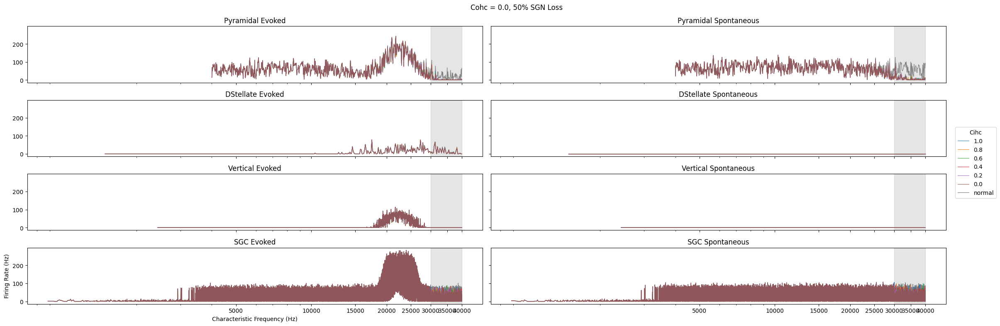

In [29]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

for sgn_loss in sgn_losses:

    for cohc in cohcs[::-1]:

        cohc = np.round(cohc, 1)

        fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True, sharey=True)

        for i, cihc in enumerate(cihcs[::-1]):

            cihc = np.round(cihc, 1)

            hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
            data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
            data_frs = pickle.load(open(data_path, 'rb'))

            axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[0,0].set_title(f"Pyramidal Evoked")
            axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[0,1].set_title(f"Pyramidal Spontaneous")

            axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[1,0].set_title(f"DStellate Evoked")
            axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[1,1].set_title(f"DStellate Spontaneous")

            axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                         zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[2,0].set_title(f"Vertical Evoked")
            axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                         zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[2,1].set_title(f"Vertical Spontaneous")

            axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[3,0].set_title(f"SGC Evoked")
            axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                        zorder=13, alpha=0.8, label=cihc, linewidth=0.9)
            axs[3,1].set_title(f"SGC Spontaneous")


        axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
        axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
        axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                    color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
        
        axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
        axs[-1,0].set_ylabel('Firing Rate (Hz)')

        # axs[0].set_xlim(29000,40000)
        # axs[0].set_ylim(top=200)

        for ax in axs.ravel():
            ax.axvspan(30000,40000, color='grey', alpha=0.2, zorder=1)

        # for i in range(1,4):
        axs[0,0].set_xscale('log')
        axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
        axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

        handles, labels = axs[0,1].get_legend_handles_labels()
        fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)
        
        fig.suptitle(f'Cohc = {cohc}, {sgn_loss}% SGN Loss')
        fig.tight_layout(rect=[0,0,0.92,1])

        

### Targeted

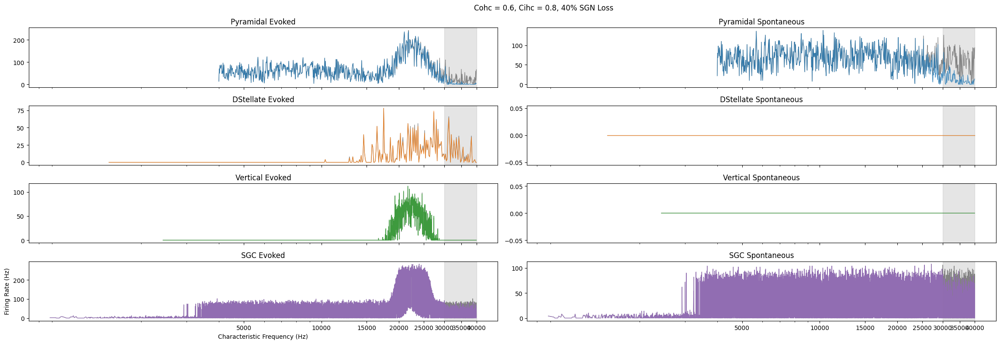

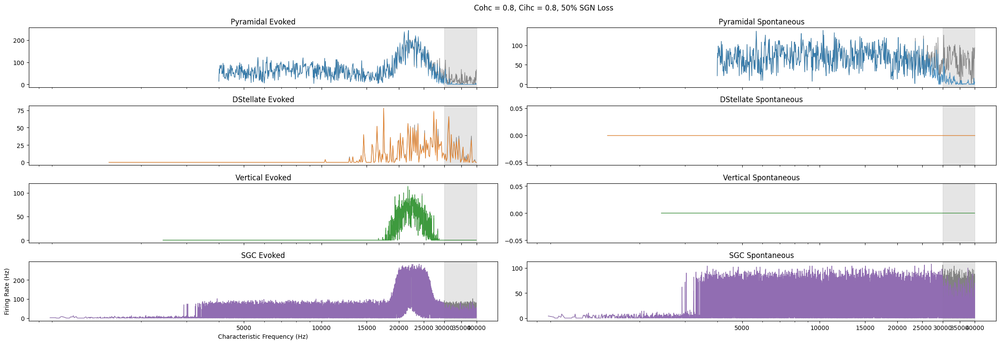

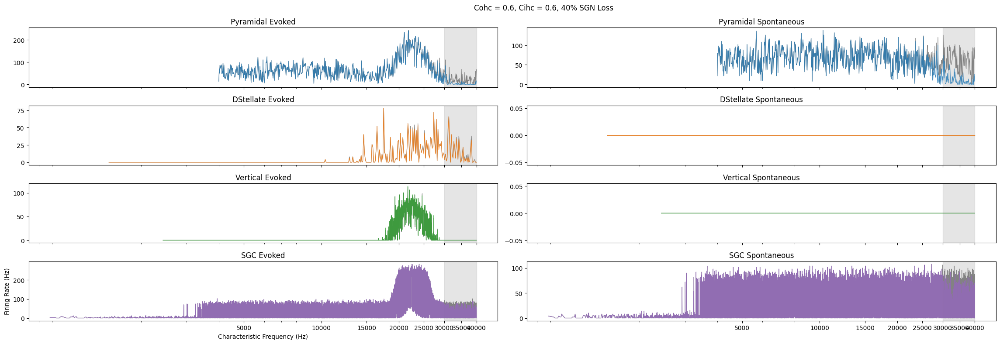

In [30]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

loss_params = [(0.6, 0.8, 40), (0.8, 0.8, 50), (0.6, 0.6, 40)]  # Cohc, Cihc, % SGN loss

for cohc, cihc, sgn_loss in loss_params:

    cohc = np.round(cohc, 1)
    cihc = np.round(cihc, 1)

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'Cohc = {cohc}, Cihc = {cihc}, {sgn_loss}% SGN Loss')
    fig.tight_layout(rect=[0,0,0.92,1])


    


### Homeostatic Factor

In [10]:
loss_limit = 30000

/tmp/ipykernel_3870616/659188381.py:14: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)


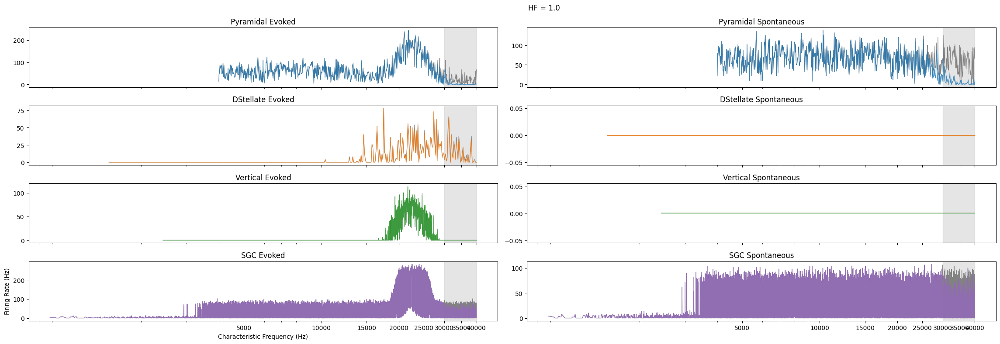

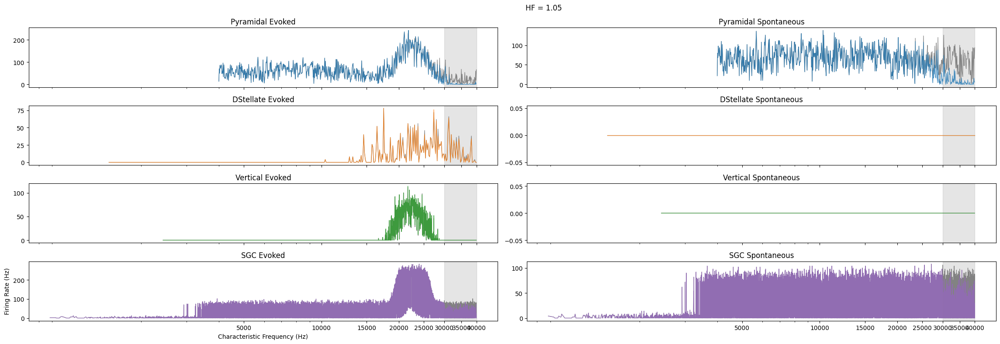

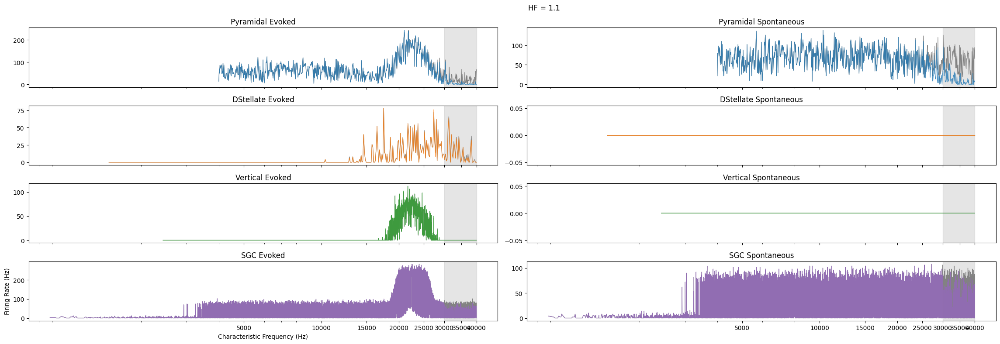

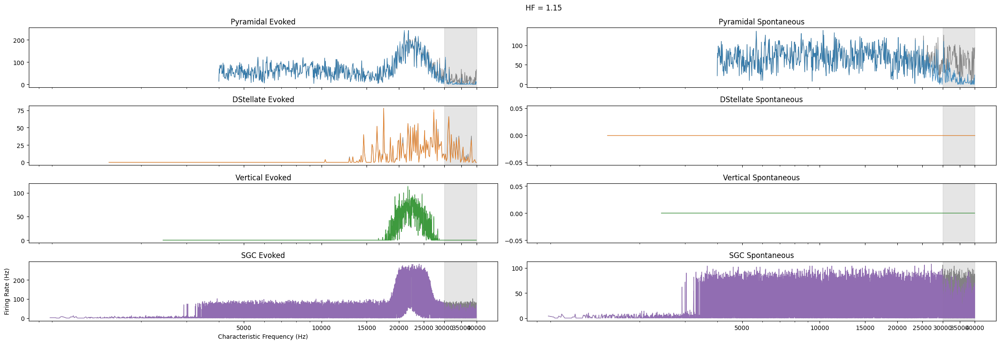

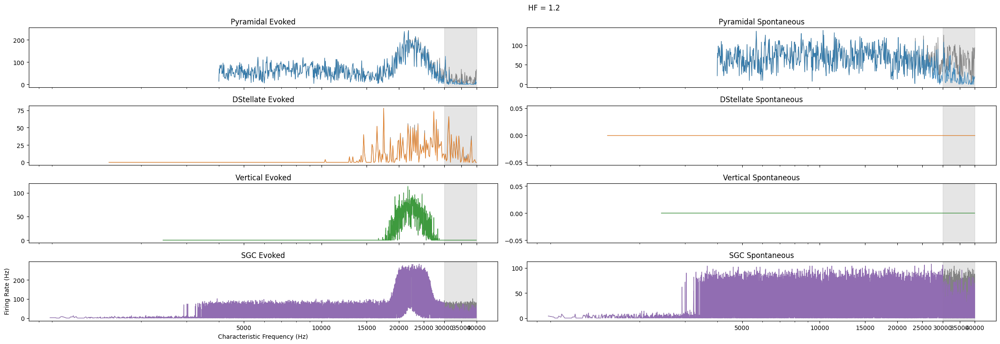

...

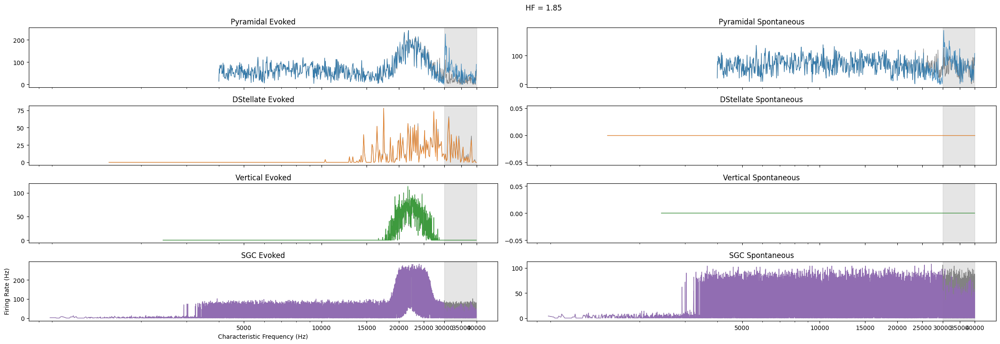

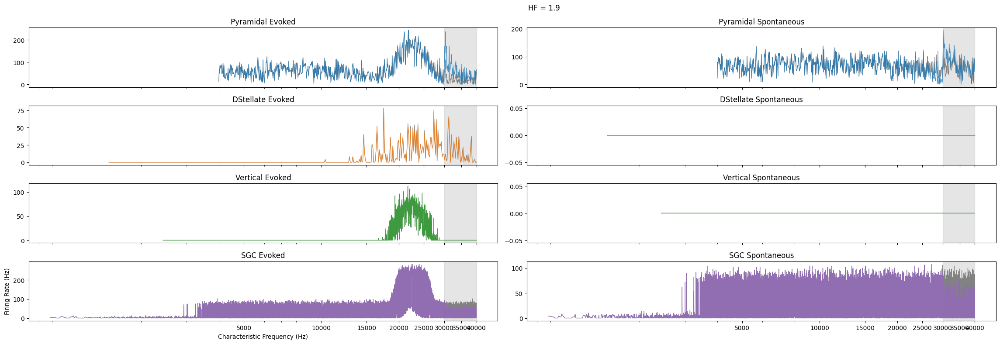

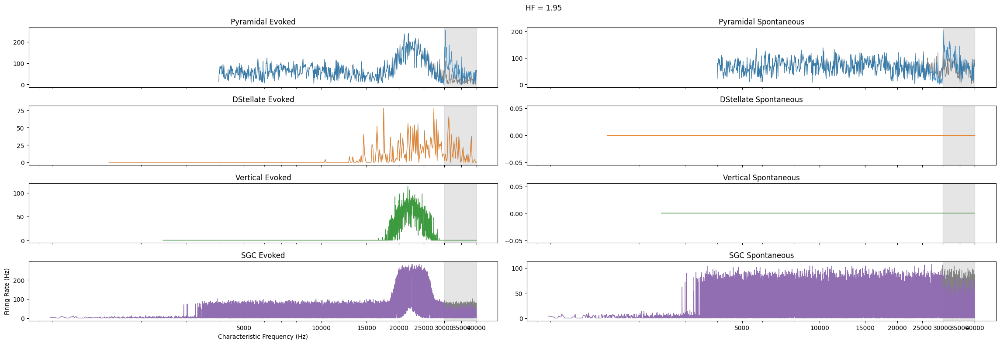

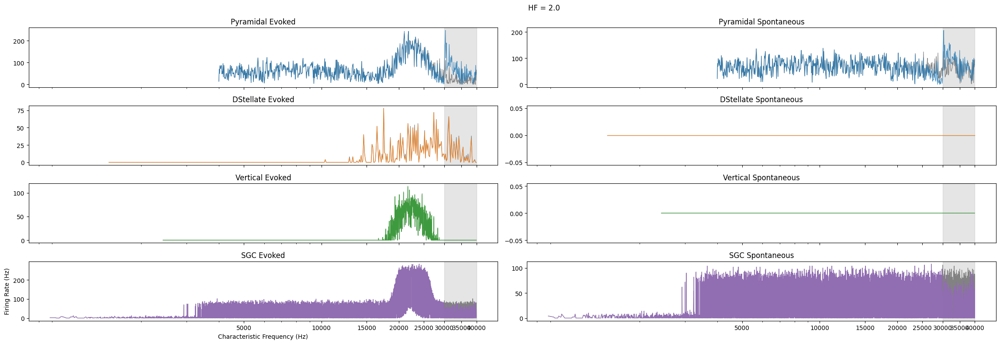

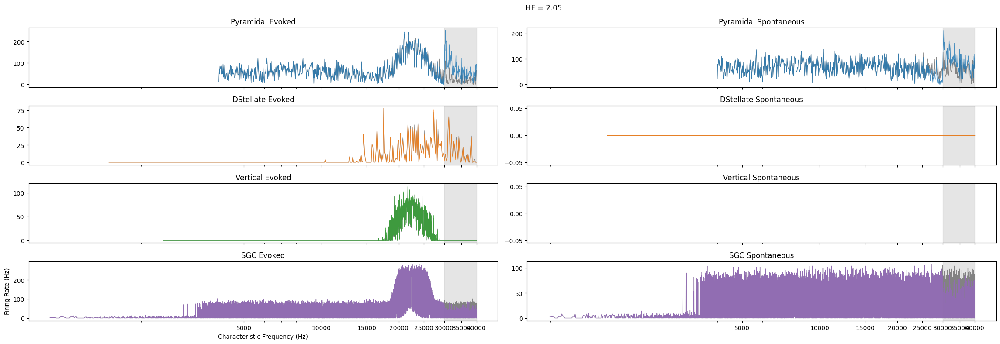

In [11]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'


cohc = 0.8
cihc = 0.8
sgn_loss = 50

hfs = np.arange(1,2.1,0.05)
hfs = [f"{float(hf):.1f}" if float(hf).is_integer() else f"{hf:g}" for hf in np.arange(1,2.1,0.05)]
hfs[-2] = '2.0'

for hf in hfs:

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'HF = {hf}')
    fig.tight_layout(rect=[0,0,0.92,1])


    


## Hearing Loss @ 15 kHz

In [31]:
loss_limit = 15000

### Targeted

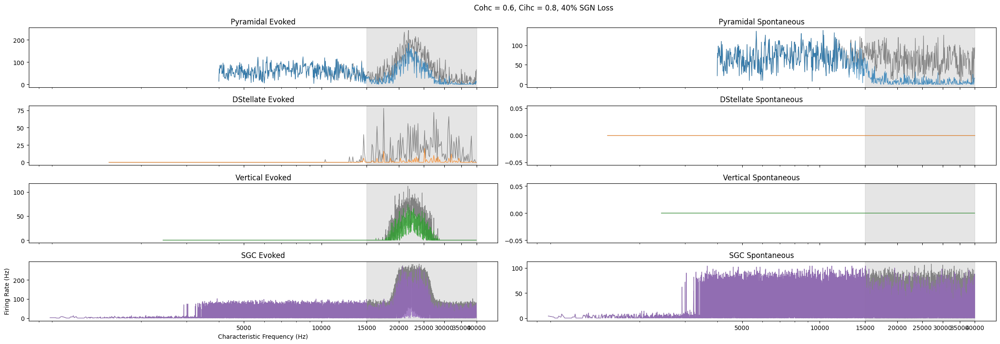

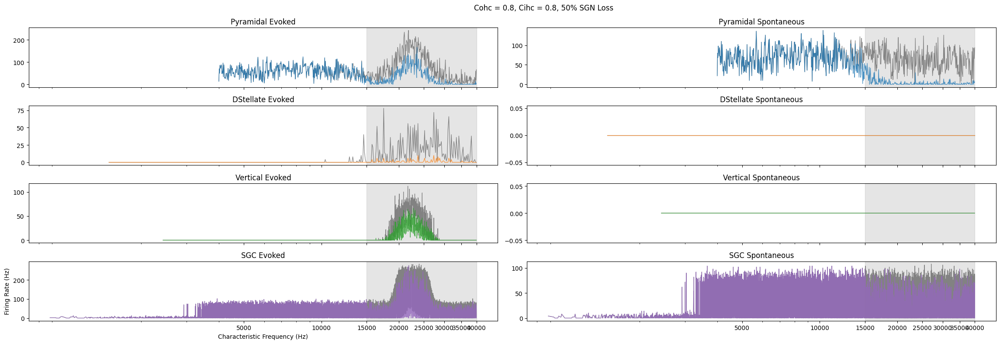

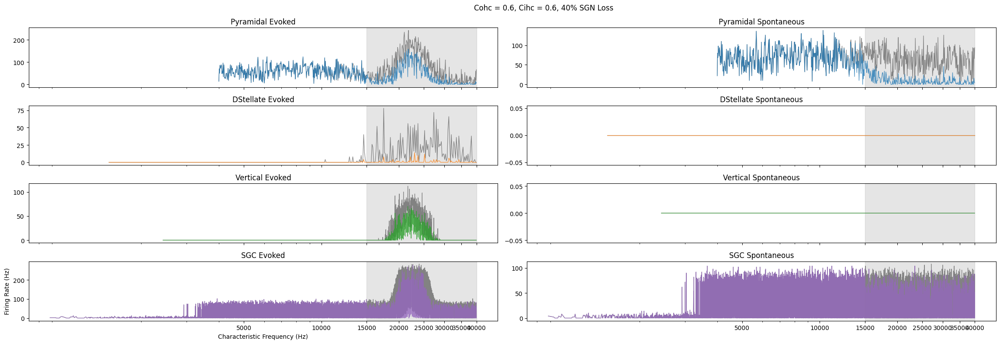

In [32]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'

loss_params = [(0.6, 0.8, 40), (0.8, 0.8, 50), (0.6, 0.6, 40)]  # Cohc, Cihc, % SGN loss

for cohc, cihc, sgn_loss in loss_params:

    cohc = np.round(cohc, 1)
    cihc = np.round(cihc, 1)

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'Cohc = {cohc}, Cihc = {cihc}, {sgn_loss}% SGN Loss')
    fig.tight_layout(rect=[0,0,0.92,1])


    


### Homeostatic Factor

/tmp/ipykernel_3870616/659188381.py:14: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)


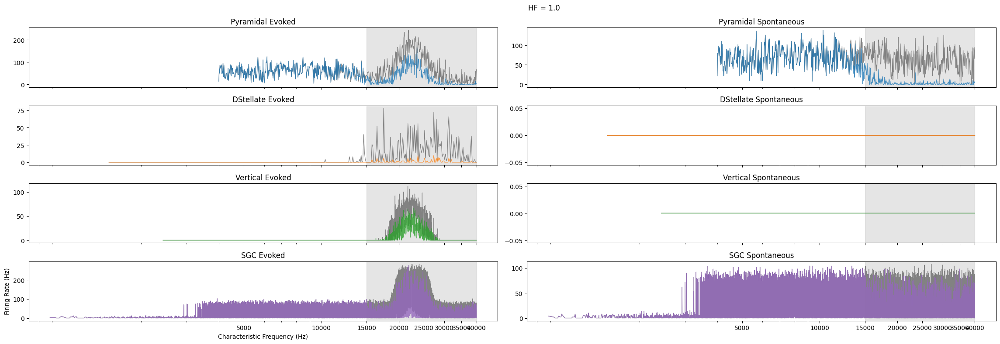

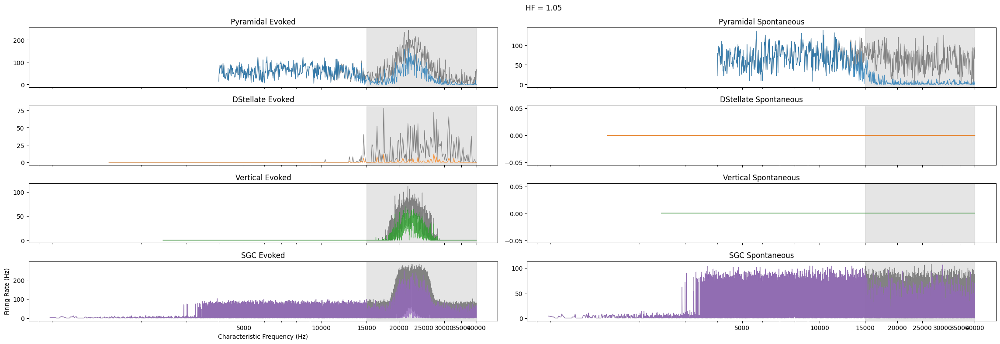

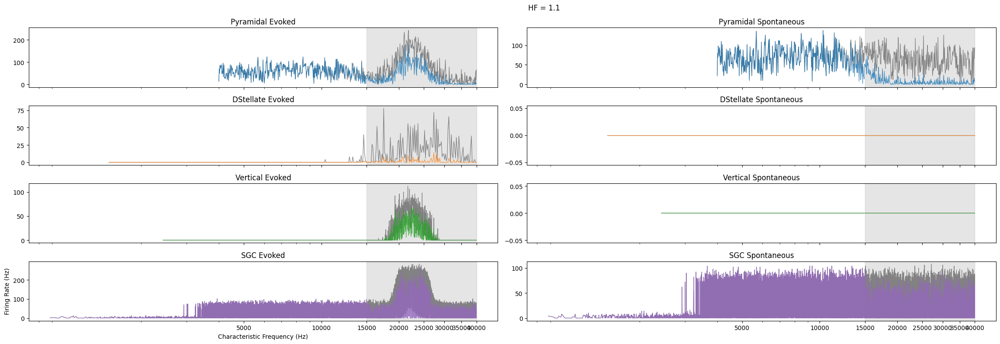

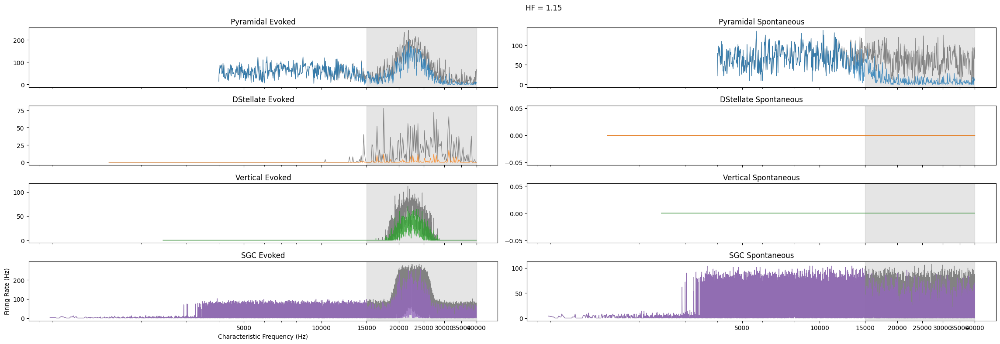

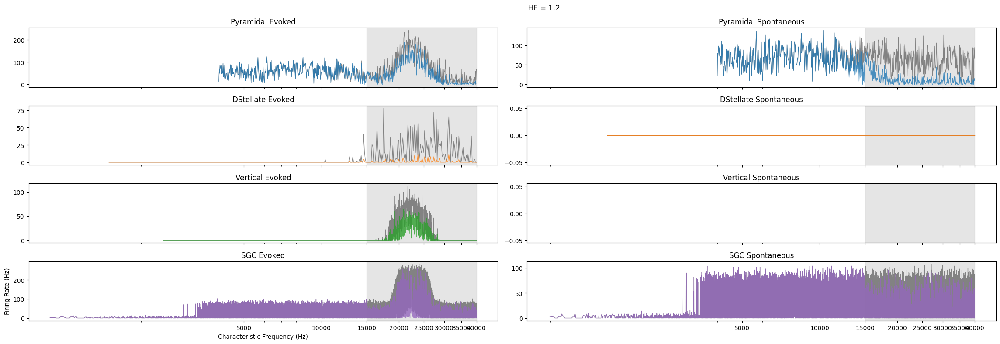

...

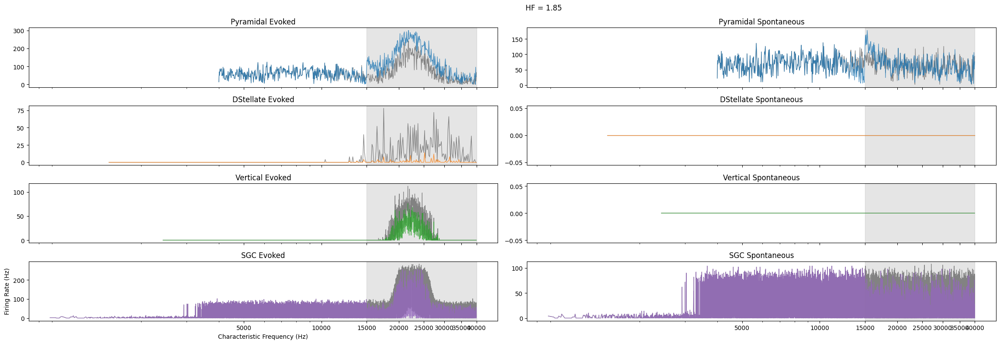

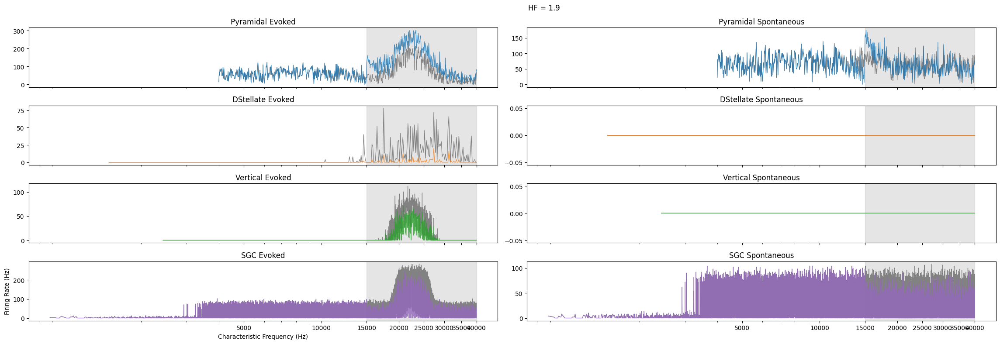

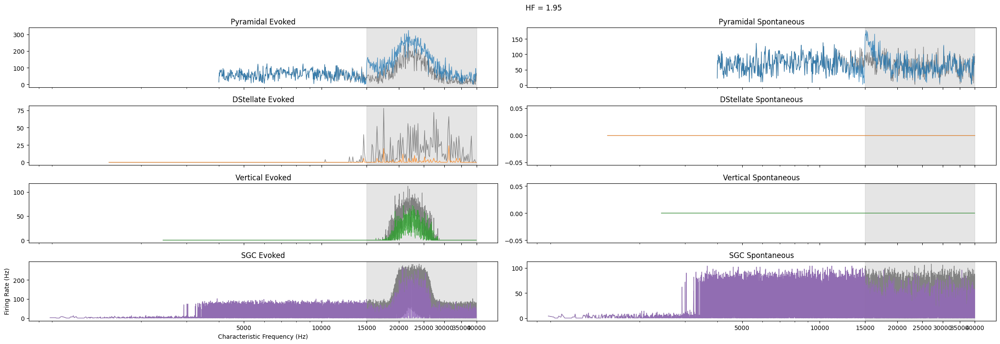

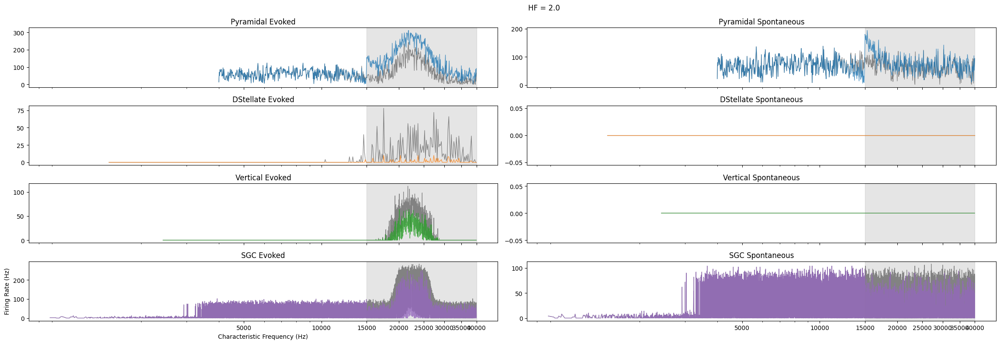

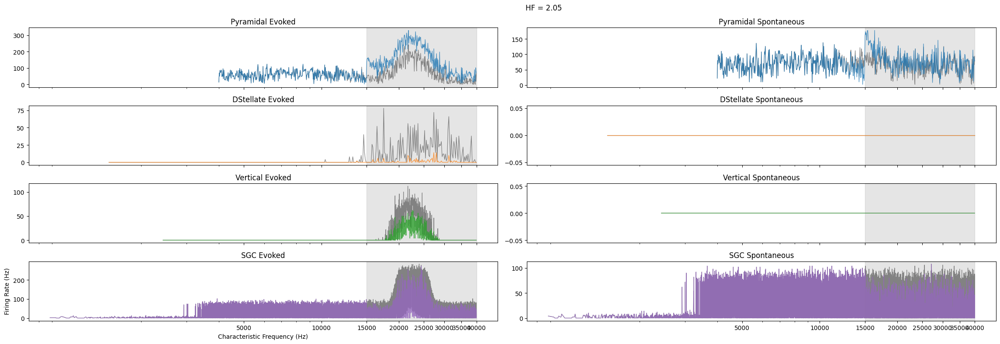

In [13]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'


cohc = 0.8
cihc = 0.8
sgn_loss = 50

hfs = np.arange(1,2.1,0.05)
hfs = [f"{float(hf):.1f}" if float(hf).is_integer() else f"{hf:g}" for hf in np.arange(1,2.1,0.05)]
hfs[-2] = '2.0'

for hf in hfs:

    fig, axs = plt.subplots(4,2,figsize=(25,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(freq,level)]], data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(freq,level)]], data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(freq,level)]], data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(freq,level)]], data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(freq,level)]], data_frs['spont_rates']['sgc'][1][(freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    axs[0,0].set_xscale('log')
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'HF = {hf}')
    fig.tight_layout(rect=[0,0,0.92,1])


    
